# PoC v2: predicción de reingreso hospitalario antes de 30 días
**Lucas Didone · Segunda iteración · 8 de octubre de 2026**  
Fundamentos de Medicina y Aplicaciones de Inteligencia Artificial

**Objetivo:** pasar de la prueba de concepto (v1) a una evaluación más cercana a una herramienta implementable. Se mantiene la misma cohorte, el mismo endpoint (`readmitted == '<30'`) y la misma unidad (internación elegible, particiones por paciente).

**Qué cambia respecto de la v1 y a qué observación de la devolución responde:**

| Cambio en v2 | Observación de la devolución |
|---|---|
| Manejo del desbalance (pesos de clase, undersampling, SMOTENC) y boosting con XGBoost y LightGBM | Pedido de la segunda iteración |
| Validación cruzada agrupada por paciente y repetida (5 folds × 3 repeticiones) para elegir modelo y medir estabilidad | "Estabilidad de las estimaciones"; validación cruzada agrupada repetida |
| Baselines clínicos LACE y HOSPITAL aproximados con variables de UCI | "Comparación con lo que ya se usa" (acción 1) |
| Recalibración en validación (Platt frente a isotónica) | Recomendaciones técnicas: recalibración |
| Curvas de decisión (`dcurves`) con costo de seguimiento explícito para justificar el cupo de 20 % | "Costo de las falsas alertas" (acción 1) |
| Métricas por subgrupo con intervalos | Recomendaciones técnicas |
| Análisis del rol de HbA1c (`A1Cresult`), en diálogo con Strack et al. (2014) | "HbA1c" |
| Diccionario de datos con sistema de origen, disponibilidad al alta y mapeo a CIE-10 / SNOMED CT / LOINC / ATC | "Disponibilidad de las variables al alta"; "Ecosistema digital en salud" (acción 3) |
| Registro de corridas con MLflow, ficha TRIPOD+AI y evaluación PROBAST | Herramientas e infraestructura |
| Esbozo de ensayo pragmático | "Impacto" (acción 4) |

**Validación temporal:** UCI no tiene fechas de internación, por lo que esta versión **no** hace partición temporal. El entrenamiento en períodos iniciales con validación y test fuera de tiempo (OOT) se implementa en el notebook separado `PoC_Reingresos_MIMIC_IV_Temporal.ipynb` (acción 2 de la devolución).

**Cómo ejecutar:** entorno de `requirements.txt` (Python 3.12 o 3.13). Abrir desde la carpeta del proyecto y ejecutar todas las celdas (≈20–30 min en CPU de 8 núcleos). El código común está en `reingresos_utils.py`. Las corridas quedan registradas en `mlruns/` (`mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`). Los artefactos se guardan en `output/v2/`.

## 1. Protocolo fijado antes de evaluar
- **Cohorte y partición idénticas a la v1** (20 años o más; sin fallecimiento, hospice ni sexo inválido; partición aleatoria por paciente 60/20/20 con las mismas semillas). Se verifica contra `output/split_assignments.csv`.
- **El test de la v1 ya fue consultado.** Se reutiliza para comparar con la v1, pero sus resultados se reportan como **evidencia secundaria**: ninguna decisión de esta versión se toma mirándolo. La evidencia fuera de muestra genuina vendrá del test OOT de MIMIC-IV.
- **Selección por validación cruzada en desarrollo (train + validación):** `StratifiedGroupKFold` de 5 folds agrupado por paciente, repetido 3 veces con semillas distintas (15 folds). Todo preprocesamiento y remuestreo se ajusta dentro de cada fold de entrenamiento.
- **Grilla en dos etapas.** Etapa 1: cada familia (LR, HGB, XGBoost, LightGBM) con sus configuraciones, sin remuestreo. Etapa 2: la mejor configuración de cada familia se cruza con las estrategias de desbalance. Los rangos de los boosters son de **baja capacidad**: en un piloto sobre train/validación, la capacidad por defecto (profundidad 6 o 31 hojas) sobreajustaba.
- **Regla de selección:** máxima AP media de CV. Entre las combinaciones cuya AP media no es inferior a la mejor menos **un error estándar** (desvío entre folds / √15), se elige la más simple: LR < HGB < boosters externos; sin remuestreo < pesos < undersampling < SMOTENC.
- **Desbalance:** pesos de clase (`class_weight='balanced'` o `scale_pos_weight` = negativos/positivos), `RandomUnderSampler` y `SMOTENC` (SMOTE para variables mixtas), ambos remuestreos a razón 1:2. **Expectativa declarada:** remuestrear o ponderar distorsiona las probabilidades y rara vez mejora AP o AUROC, que dependen solo del orden. Por eso se recalibra.
- **Recalibración:** el modelo elegido se reentrena en train y se recalibra en validación. Platt frente a isotónica, elegido por Brier con ajuste cruzado dentro de validación.
- **Baselines clínicos:** LACE y HOSPITAL aproximados (UCI no tiene hemoglobina ni sodio, ni días exactos de visitas previas).
- **Criterios de continuidad (test, secundarios):** los de la v1 (AP/prevalencia ≥ 1,5; lift@20 % ≥ 1,5; límite inferior IC95 % de AP−prevalencia > 0 y de AUROC > 0,5) **más** valor agregado frente a LACE: límite inferior del IC95 % de (AP modelo − AP LACE) > 0.
- **IC95 %:** 300 remuestreos de pacientes completos (bootstrap agrupado), con diferencias pareadas.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '4')
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
os.environ.setdefault('MLFLOW_LOGGING_LEVEL', 'WARNING')
from pathlib import Path
import sys, json, hashlib, zipfile, urllib.request, time, platform, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, lightgbm, imblearn, dcurves
from IPython.display import display, Markdown
from scipy.stats import norm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
threadpool_limits(limits=4)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
logging.getLogger('mlflow').setLevel(logging.WARNING)
BASE = Path.cwd()
sys.path.insert(0, str(BASE))
import reingresos_utils as ru
from reingresos_utils import metrics, top_metrics
SEED = ru.SEED
N_JOBS = min(6, os.cpu_count() or 2)
DATA = BASE / 'data'; OUT = BASE / 'output' / 'v2'; MLRUNS = BASE / 'mlruns'
DATA.mkdir(exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
try:
    import mlflow; mlflow_version = mlflow.__version__
except ImportError:
    mlflow_version = None
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'xgboost': xgboost.__version__, 'lightgbm': lightgbm.__version__,
            'imbalanced-learn': imblearn.__version__, 'mlflow': mlflow_version}
print(versions, '| procesos paralelos:', N_JOBS)

{'python': '3.13.5', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'imbalanced-learn': '0.14.2', 'mlflow': '3.17.0'} | procesos paralelos: 6


## 2. Fuente, cohorte y partición (igual que la v1)
Fuente: Clore, Cios, DeShazo y Strack (2014), *Diabetes 130-US Hospitals for Years 1999–2008*, UCI. DOI: https://doi.org/10.24432/C5230J. Licencia CC BY 4.0. `?` indica faltante; la cadena `None` en HbA1c y glucemia significa **prueba no realizada** y se conserva como categoría.

In [2]:
URL = 'https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip'
archive = DATA / 'diabetes.zip'
if not archive.exists():
    urllib.request.urlretrieve(URL, archive)
sha256 = hashlib.sha256(archive.read_bytes()).hexdigest()
with zipfile.ZipFile(archive) as z:
    with z.open('diabetic_data.csv') as f:
        raw = pd.read_csv(f, keep_default_na=False, na_values=['?'], low_memory=False)
assert raw.encounter_id.is_unique
print('SHA256 del ZIP:', sha256)
print('Filas, columnas:', raw.shape, '| Pacientes únicos:', raw.patient_nbr.nunique())

cohort = raw.copy()
flow = [{'etapa': 'Datos originales', 'episodios': len(cohort), 'excluidos': 0}]
for name, keep in [
    ('Edad ≥20 años', lambda d: ~d.age.isin(['[0-10)', '[10-20)'])),
    ('Sin fallecimiento ni hospice', lambda d: ~d.discharge_disposition_id.isin([11,13,14,19,20,21])),
    ('Sexo registrado válido', lambda d: d.gender != 'Unknown/Invalid')]:
    n0 = len(cohort)
    cohort = cohort.loc[keep(cohort)].copy()
    flow.append({'etapa': name, 'episodios': len(cohort), 'excluidos': n0-len(cohort)})
cohort = cohort.reset_index(drop=True)
y = cohort.readmitted.eq('<30').astype(int)
groups = cohort.patient_nbr
print('Prevalencia de la cohorte:', f'{y.mean():.2%}')
display(pd.DataFrame(flow))

SHA256 del ZIP: f82ac129da2ddd2299391ff6fbae3a6a58b3edcf59ac9d7bd480c00fe453112a
Filas, columnas: (101766, 50) | Pacientes únicos: 71518


Prevalencia de la cohorte: 11.44%


,etapa,episodios,excluidos
0,Datos originales,101766,0
1,Edad ≥20 años,100914,852
2,Sin fallecimiento ni hospice,98493,2421
3,Sexo registrado válido,98490,3


In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(gss.split(cohort, groups=groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED+1)
tr_local, va_local = next(gss2.split(cohort.iloc[dev_idx], groups=groups.iloc[dev_idx]))
train_idx, val_idx = dev_idx[tr_local], dev_idx[va_local]
parts = {'train': train_idx, 'validation': val_idx, 'test': test_idx}
for a, b in [('train','validation'), ('train','test'), ('validation','test')]:
    assert set(groups.iloc[parts[a]]).isdisjoint(groups.iloc[parts[b]])
v1_split = BASE / 'output' / 'split_assignments.csv'
if v1_split.exists():
    v1 = pd.read_csv(v1_split).set_index('encounter_id').partition
    now = pd.Series({cohort.encounter_id.iloc[i]: k for k, ix in parts.items() for i in ix})
    assert now.sort_index().equals(v1.sort_index()), 'La partición no coincide con la v1'
    print('Partición idéntica a la v1 (split_assignments.csv). Pacientes compartidos: 0')
display(pd.DataFrame([{'partición': k, 'episodios': len(ix), 'pacientes': groups.iloc[ix].nunique(),
                       'positivos': int(y.iloc[ix].sum()), 'prevalencia': y.iloc[ix].mean()}
                      for k, ix in parts.items()]).round(4))

Partición idéntica a la v1 (split_assignments.csv). Pacientes compartidos: 0


,partición,episodios,pacientes,positivos,prevalencia
0,train,58870,41586,6758,0.1148
1,validation,19849,13862,2254,0.1136
2,test,19771,13863,2259,0.1143


## 3. Features
Se conservan las features de la v1 (sin `race` ni `payer_code`; se eliminan en train las columnas con más de 80 % de faltantes o constantes). Se agregan tres variables derivadas: el **grupo diagnóstico** de `diag_1`, `diag_2` y `diag_3` según la agrupación por capítulos CIE-9 de Strack et al. (2014). Estos grupos también son el punto de partida del mapeo a CIE-10 de la sección 11.

In [4]:
excluded = ['encounter_id','patient_nbr','readmitted','race','payer_code']
X = cohort.drop(columns=excluded).copy()
for c in ['admission_type_id','discharge_disposition_id','admission_source_id']:
    X[c] = X[c].astype(str)
group_cols = [f'diag_{k}_group' for k in (1, 2, 3)]
for k in (1, 2, 3):
    X[f'diag_{k}_group'] = cohort[f'diag_{k}'].map(ru.icd9_group)
train_missing = X.iloc[train_idx].isna().mean()
dropped_missing = train_missing[train_missing > 0.80].index.tolist()
constant = [c for c in X if X.iloc[train_idx][c].nunique(dropna=False) <= 1]
dropped = sorted(set(dropped_missing + constant))
X = X.drop(columns=dropped)
num = X.select_dtypes(include='number').columns.tolist()
cat = [c for c in X if c not in num]
v1_cols = [c for c in X if c not in group_cols]
Xtr, Xva, Xte = X.iloc[train_idx], X.iloc[val_idx], X.iloc[test_idx]
ytr, yva, yte = y.iloc[train_idx], y.iloc[val_idx], y.iloc[test_idx]
print('Excluidas por faltantes/constancia (aprendido en train):', dropped)
print(f'Features v2: {X.shape[1]} ({len(num)} numéricas, {len(cat)} categóricas); v1: {len(v1_cols)}')
display(pd.crosstab(X.diag_1_group, y, normalize='index').rename(columns={0:'no', 1:'reingreso <30'})
        .join(X.diag_1_group.value_counts().rename('episodios')).round(3))

Excluidas por faltantes/constancia (aprendido en train): ['citoglipton', 'examide', 'weight']
Features v2: 45 (8 numéricas, 37 categóricas); v1: 42


,no,reingreso <30,episodios
diag_1_group,,,
Circulatory,0.883,0.117,29674
Diabetes,0.862,0.138,8051
Digestive,0.892,0.108,9314
Genitourinary,0.889,0.111,4990
Injury,0.876,0.124,6825
Missing,0.750,0.250,20
Musculoskeletal,0.905,0.095,4932
Neoplasms,0.892,0.108,3128
Other,0.883,0.117,17677


## 4. Baselines clínicos: LACE y HOSPITAL (aproximados)
Son los scores de reingreso que un equipo puede calcular a mano. Sirven para saber si el modelo aporta algo frente a una herramienta simple.

| Score | Componente | Definición original | Aproximación con UCI |
|---|---|---|---|
| LACE (van Walraven 2010) | **L** estancia | días de internación (0–7 puntos) | `time_in_hospital` |
| | **A** agudeza | ingreso urgente o emergente (3) | `admission_type_id` 1 o 7, u origen guardia (`admission_source_id` 7) |
| | **C** comorbilidad | Charlson (0–5) | Charlson de Quan con `diag_1..3` (solo 3 diagnósticos: subestima) |
| | **E** guardias | visitas a guardia en 6 meses previos (0–4) | `number_emergency` (año previo) |
| HOSPITAL (Donzé 2013) | **H** hemoglobina < 12 al alta (1) | | **no disponible** (0) |
| | **O** alta de oncología (2) | | algún diagnóstico CIE-9 140–239 |
| | **S** sodio < 135 al alta (1) | | **no disponible** (0) |
| | **P** procedimiento (1) | | `num_procedures > 0` |
| | **I** ingreso no electivo (1) | | `admission_type_id` 1, 2 o 7 |
| | **T** internaciones previas 12 meses (0/2/5) | | `number_inpatient` |
| | **A** estancia ≥ 5 días (2) | | `time_in_hospital ≥ 5` |

Cada score se convierte en probabilidad con una logística de una variable ajustada en train. El orden (AUROC, AP, lift) es el del score; la probabilidad solo hace comparable el Brier y la curva de decisión. En MIMIC-IV ambos scores se calculan completos.

Validación (no participa en la selección, que usa CV):


,AUROC,AP,Brier,Precision@20,Recall@20,Lift@20
Prevalencia constante,0.5000,0.1136,0.1007,0.1108,0.1952,0.9760
LACE (aprox.),0.5684,0.1390,0.1000,0.1559,0.2746,1.3730
HOSPITAL (parcial),0.5892,0.1557,0.0992,0.1662,0.2928,1.4640
Solo utilización previa (LR),0.6055,0.1860,0.0980,0.1887,0.3323,1.6614
v1: logística,0.6532,0.2195,0.0965,0.2093,0.3687,1.8433


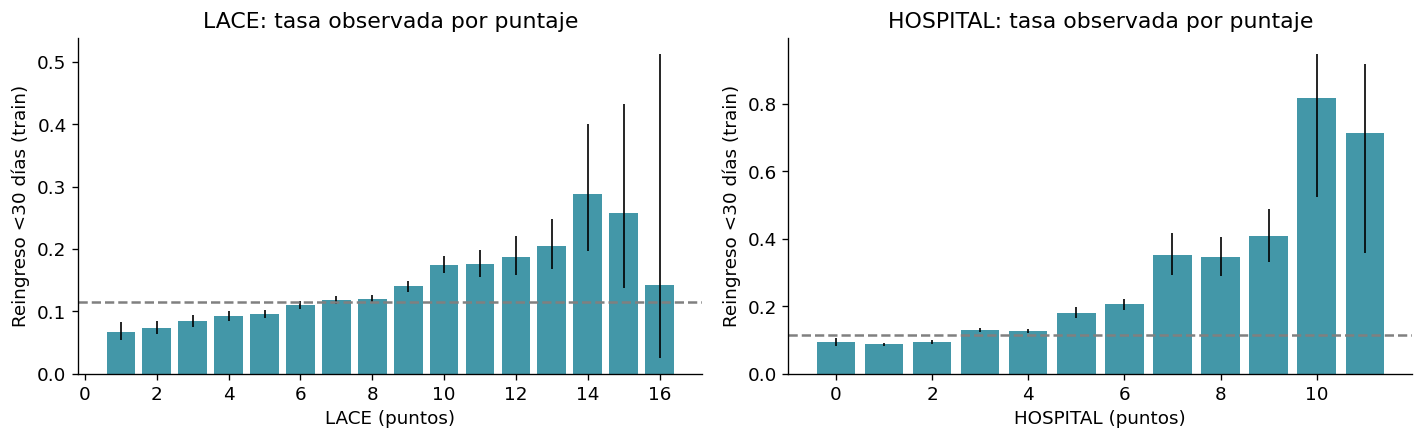

In [5]:
flags = ru.comorbidity_flags(cohort.diag_1, 9)
for k in (2, 3):
    flags |= ru.comorbidity_flags(cohort[f'diag_{k}'], 9)
cohort['charlson'] = ru.charlson_score(flags)
emergent = cohort.admission_type_id.isin([1, 7]) | cohort.admission_source_id.eq(7)
oncology = pd.concat([cohort[f'diag_{k}'].map(ru.icd9_group).eq('Neoplasms') for k in (1,2,3)], axis=1).any(axis=1)
cohort['LACE'] = ru.lace_score(cohort.time_in_hospital, emergent, cohort.charlson, cohort.number_emergency)
cohort['HOSPITAL'] = ru.hospital_score(np.nan, oncology, np.nan, cohort.num_procedures > 0,
                                       cohort.admission_type_id.isin([1, 2, 7]),
                                       cohort.number_inpatient, cohort.time_in_hospital)
score_models = {}
for s in ['LACE', 'HOSPITAL']:
    score_models[s] = LogisticRegression().fit(cohort.loc[train_idx, [s]], ytr)
def score_prob(s, idx):
    return score_models[s].predict_proba(cohort.loc[idx, [s]])[:, 1]

history = ['number_inpatient', 'number_emergency', 'number_outpatient']
only_history = ru.make_v1_model('LR', history, num, cat).fit(Xtr[history], ytr)
v1_lr = ru.make_v1_model('LR', v1_cols, num, cat).fit(Xtr[v1_cols], ytr)
baseline_val = {
    'Prevalencia constante': metrics(yva, np.full(len(yva), ytr.mean())),
    'LACE (aprox.)': metrics(yva, score_prob('LACE', val_idx)),
    'HOSPITAL (parcial)': metrics(yva, score_prob('HOSPITAL', val_idx)),
    'Solo utilización previa (LR)': metrics(yva, only_history.predict_proba(Xva[history])[:, 1]),
    'v1: logística': metrics(yva, v1_lr.predict_proba(Xva[v1_cols])[:, 1])}
print('Validación (no participa en la selección, que usa CV):')
display(pd.DataFrame(baseline_val).T.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, s in zip(axes, ['LACE', 'HOSPITAL']):
    t = pd.DataFrame({'score': cohort.loc[train_idx, s], 'y': ytr}).groupby('score').y.agg(['mean', 'size'])
    lo, hi = ru.wilson_ci(t['mean']*t['size'], t['size'])
    ax.bar(t.index, t['mean'], color='#147D92', alpha=.8)
    ax.errorbar(t.index, t['mean'], yerr=[t['mean']-lo, hi-t['mean']], fmt='none', color='k', lw=1)
    ax.axhline(ytr.mean(), ls='--', color='gray')
    ax.set(xlabel=f'{s} (puntos)', ylabel='Reingreso <30 días (train)', title=f'{s}: tasa observada por puntaje')
fig.tight_layout(); fig.savefig(OUT/'baselines_scores.png', dpi=170); plt.show()

## 5. Desbalance y grilla de modelos con validación cruzada agrupada repetida
Prevalencia ≈ 11 %. Estrategias comparadas, todas dentro de un `Pipeline` de imbalanced-learn, de modo que el remuestreo se aplica **solo al ajustar** cada fold de entrenamiento y nunca al predecir:

| Estrategia | Implementación |
|---|---|
| `none` | sin cambios: probabilidades bajo la prevalencia observada |
| `weights` | LR y HGB: `class_weight='balanced'`; XGBoost y LightGBM: `scale_pos_weight` = negativos/positivos del fold |
| `under` | `RandomUnderSampler` hasta 1 positivo cada 2 negativos (descarta ≈ 75 % de negativos) |
| `smote` | `SMOTENC` hasta 1:2; interpola numéricas y toma la moda de los vecinos en categóricas |

Modelos: LR (one-hot), HGB (el boosting de la v1), XGBoost y LightGBM con splits categóricos nativos. La tabla siguiente muestra el efecto de cada remuestreo sobre el train completo.

In [6]:
prep = ru.ordinal_preprocessor(num, cat).fit(Xtr)
Ztr = prep.transform(Xtr)
cat_idx = list(range(len(num), len(num)+len(cat)))
counts = {'none': np.bincount(ytr)}
for s, sampler in [('under', ru.RandomUnderSampler(sampling_strategy=ru.SAMPLING_RATIO, random_state=SEED)),
                   ('smote', ru.SMOTENC(categorical_features=cat_idx, sampling_strategy=ru.SAMPLING_RATIO,
                                        random_state=SEED))]:
    counts[s] = np.bincount(sampler.fit_resample(Ztr, ytr)[1])
display(pd.DataFrame(counts, index=['negativos', 'positivos']).T.assign(
    prevalencia=lambda d: d.positivos/(d.positivos+d.negativos)).round(3))

,negativos,positivos,prevalencia
none,52112,6758,0.115
under,13516,6758,0.333
smote,52112,26056,0.333


In [7]:
XGB_GRID = [dict(max_depth=d, colsample_bytree=c) for d in (3, 4) for c in (0.5, 0.8)]
LGBM_GRID = [dict(num_leaves=l, colsample_bytree=c) for l in (7, 15) for c in (0.5, 0.8)]
Xdev = X.iloc[dev_idx].reset_index(drop=True)
ydev = y.iloc[dev_idx].reset_index(drop=True)
gdev = groups.iloc[dev_idx].reset_index(drop=True)
folds = ru.repeated_group_folds(ydev, gdev, n_splits=5, n_repeats=3, seed=SEED)
for fid, a, b in folds:
    assert set(gdev.iloc[a]).isdisjoint(gdev.iloc[b])
print(f'{len(folds)} folds sobre {len(ydev):,} episodios de desarrollo; ningún paciente cruza folds.')

stage1 = ru.build_grid(XGB_GRID, LGBM_GRID, strategies=('none',))
t0 = time.perf_counter()
cv1 = ru.evaluate_folds(Xdev, ydev, folds, stage1, num, cat, seed=SEED, n_jobs=N_JOBS)
print(f'Etapa 1: {len(stage1)} configuraciones × {len(folds)} folds en {time.perf_counter()-t0:.0f} s')
sum1 = ru.summarize_cv(cv1, stage1)
display(sum1[['kind', 'AP_mean', 'AP_std', 'AUROC_mean', 'Brier_mean', 'Lift@20_mean']].round(4))
best_per_family = sum1.groupby('kind').AP_mean.idxmax()
best_configs = set(sum1.loc[best_per_family, 'config'])
print('Mejor configuración por familia:', sorted(best_configs))

15 folds sobre 78,719 episodios de desarrollo; ningún paciente cruza folds.


Etapa 1: 10 configuraciones × 15 folds en 253 s


,kind,AP_mean,AP_std,AUROC_mean,Brier_mean,Lift@20_mean
LGBM-num_leaves15-colsample_bytree0.5 | none,LGBM,0.2263,0.0049,0.6661,0.0967,1.9111
LGBM-num_leaves7-colsample_bytree0.5 | none,LGBM,0.2253,0.0045,0.6667,0.0967,1.9178
XGB-max_depth3-colsample_bytree0.5 | none,XGB,0.2239,0.0045,0.6646,0.0968,1.9041
XGB-max_depth4-colsample_bytree0.5 | none,XGB,0.2229,0.0051,0.6628,0.0970,1.8932
LGBM-num_leaves7-colsample_bytree0.8 | none,LGBM,0.2226,0.0053,0.6635,0.0969,1.8956
LGBM-num_leaves15-colsample_bytree0.8 | none,LGBM,0.2210,0.0051,0.6610,0.0971,1.8788
HGB | none,HGB,0.2205,0.0060,0.6596,0.0971,1.8910
XGB-max_depth3-colsample_bytree0.8 | none,XGB,0.2181,0.0044,0.6595,0.0972,1.8800
LR | none,LR,0.2161,0.0050,0.6569,0.0974,1.8723
XGB-max_depth4-colsample_bytree0.8 | none,XGB,0.2132,0.0045,0.6534,0.0977,1.8490


Mejor configuración por familia: ['HGB', 'LGBM-num_leaves15-colsample_bytree0.5', 'LR', 'XGB-max_depth3-colsample_bytree0.5']


In [8]:
stage2 = [c for c in ru.build_grid(XGB_GRID, LGBM_GRID)
          if c['config'] in best_configs and c['strategy'] != 'none']
t0 = time.perf_counter()
cv2 = ru.evaluate_folds(Xdev, ydev, folds, stage2, num, cat, seed=SEED, n_jobs=N_JOBS)
print(f'Etapa 2: {len(stage2)} combinaciones × {len(folds)} folds en {time.perf_counter()-t0:.0f} s')
combos = stage1 + stage2
cv_all = pd.concat([cv1, cv2], ignore_index=True)
summary = ru.summarize_cv(cv_all, combos)
chosen_name, best_name, se_best, candidates = ru.select_one_se(summary)
chosen = next(c for c in combos if c['name'] == chosen_name)
cols = ['kind', 'strategy', 'AP_mean', 'AP_std', 'AUROC_mean', 'AUROC_std', 'Brier_mean',
        'Lift@20_mean', 'Recall@20_mean', 'seconds_mean']
display(summary[cols].round(4))
print(f'Mejor AP media: {best_name} ({summary.loc[best_name, "AP_mean"]:.4f}); EE = {se_best:.4f}')
print('Candidatas dentro de 1 EE:', candidates.index.tolist())
print('MODELO ELEGIDO (regla de 1 EE):', chosen_name)
uri = ru.mlflow_log_summary(summary, 'reingresos_uci_v2_cv', MLRUNS,
                            common_params={'cv': '5x3 StratifiedGroupKFold', 'seed': SEED,
                                           'sampling_ratio': ru.SAMPLING_RATIO, 'n_features': X.shape[1]},
                            tags={'dataset': 'UCI Diabetes 130-US', 'sha256': sha256[:12]})
print('Corridas registradas en MLflow:', uri)
summary.to_csv(OUT/'cv_resumen.csv', index_label='combinacion')
cv_all.to_csv(OUT/'cv_folds.csv', index=False)

Etapa 2: 12 combinaciones × 15 folds en 667 s


,kind,strategy,AP_mean,AP_std,AUROC_mean,AUROC_std,Brier_mean,Lift@20_mean,Recall@20_mean,seconds_mean
LGBM-num_leaves15-colsample_bytree0.5 | none,LGBM,none,0.2263,0.0049,0.6661,0.0054,0.0967,1.9111,0.3823,9.7065
LGBM-num_leaves7-colsample_bytree0.5 | none,LGBM,none,0.2253,0.0045,0.6667,0.0053,0.0967,1.9178,0.3836,8.2327
LGBM-num_leaves15-colsample_bytree0.5 | weights,LGBM,weights,0.2245,0.0049,0.6647,0.0058,0.2075,1.9117,0.3824,9.4874
XGB-max_depth3-colsample_bytree0.5 | none,XGB,none,0.2239,0.0045,0.6646,0.0062,0.0968,1.9041,0.3809,8.1839
XGB-max_depth4-colsample_bytree0.5 | none,XGB,none,0.2229,0.0051,0.6628,0.0065,0.0970,1.8932,0.3787,9.8470
LGBM-num_leaves7-colsample_bytree0.8 | none,LGBM,none,0.2226,0.0053,0.6635,0.0059,0.0969,1.8956,0.3792,7.1727
LGBM-num_leaves15-colsample_bytree0.8 | none,LGBM,none,0.2210,0.0051,0.6610,0.0058,0.0971,1.8788,0.3758,9.2244
LGBM-num_leaves15-colsample_bytree0.5 | under,LGBM,under,0.2208,0.0044,0.6648,0.0050,0.1420,1.9026,0.3806,6.3523
HGB | none,HGB,none,0.2205,0.0060,0.6596,0.0065,0.0971,1.8910,0.3782,8.2883
XGB-max_depth3-colsample_bytree0.5 | weights,XGB,weights,0.2205,0.0046,0.6625,0.0061,0.2135,1.9008,0.3802,8.3399


Mejor AP media: LGBM-num_leaves15-colsample_bytree0.5 | none (0.2263); EE = 0.0013
Candidatas dentro de 1 EE: ['LGBM-num_leaves15-colsample_bytree0.5 | none', 'LGBM-num_leaves7-colsample_bytree0.5 | none']
MODELO ELEGIDO (regla de 1 EE): LGBM-num_leaves15-colsample_bytree0.5 | none


Corridas registradas en MLflow: sqlite:////Users/lucasdidone/Documents/MIA/MEDIA/Proyecto_Reingresos_PoC/mlruns/mlflow.db


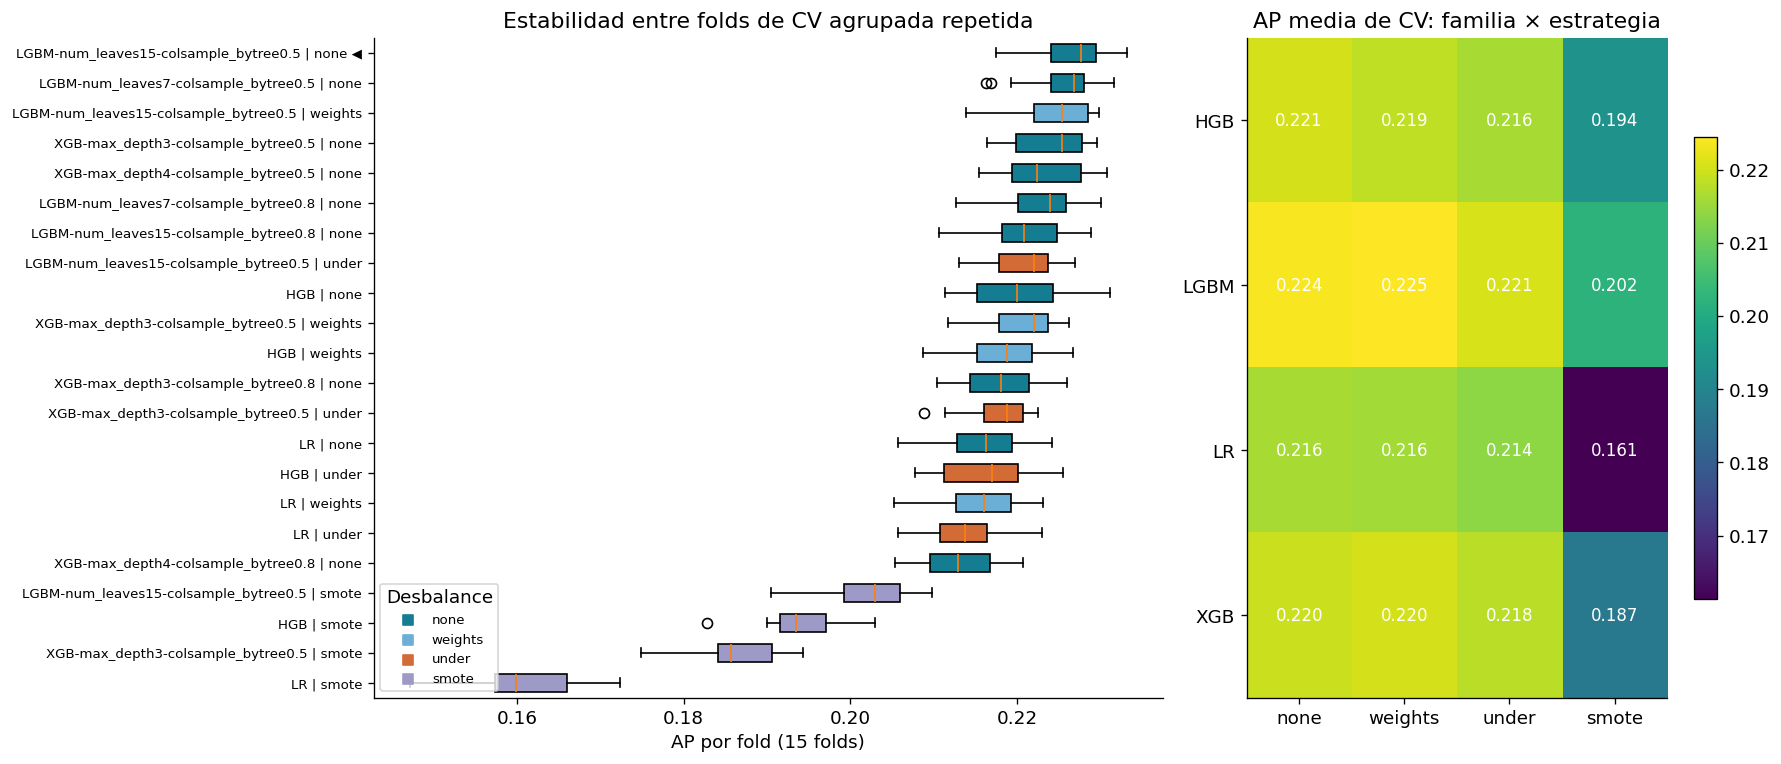

Rango de AP entre folds del modelo elegido: 0.0157 (DE 0.0049). Diferencia validación→test en la v1 (LR): -0.0023


In [9]:
order = summary.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [3, 2]})
data = [cv_all.loc[cv_all.combo == n, 'AP'].values for n in order][::-1]
colors = {'none': '#147D92', 'weights': '#6BAED6', 'under': '#D36B36', 'smote': '#9E9AC8'}
bp = axes[0].boxplot(data, vert=False, patch_artist=True, widths=.6)
for patch, n in zip(bp['boxes'], order[::-1]):
    patch.set_facecolor(colors[summary.loc[n, 'strategy']])
axes[0].set_yticks(range(1, len(order)+1), [n + (' ◀' if n == chosen_name else '') for n in order[::-1]], fontsize=8)
axes[0].set(xlabel='AP por fold (15 folds)', title='Estabilidad entre folds de CV agrupada repetida')
for s, c in colors.items():
    axes[0].scatter([], [], color=c, marker='s', label=s)
axes[0].legend(title='Desbalance', fontsize=8, loc='lower left')
piv = summary.pivot_table(index='kind', columns='strategy', values='AP_mean').reindex(
    columns=['none', 'weights', 'under', 'smote'])
im = axes[1].imshow(piv.values, cmap='viridis', aspect='auto')
axes[1].set_xticks(range(piv.shape[1]), piv.columns); axes[1].set_yticks(range(piv.shape[0]), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        axes[1].text(j, i, f'{piv.values[i, j]:.3f}', ha='center', va='center', color='w', fontsize=10)
axes[1].set_title('AP media de CV: familia × estrategia')
fig.colorbar(im, ax=axes[1], shrink=.7)
fig.tight_layout(); fig.savefig(OUT/'cv_estabilidad.png', dpi=170); plt.show()
spread = cv_all.groupby('combo').AP.agg(lambda s: s.max() - s.min())
print(f'Rango de AP entre folds del modelo elegido: {spread[chosen_name]:.4f} '
      f'(DE {summary.loc[chosen_name, "AP_std"]:.4f}). Diferencia validación→test en la v1 (LR): {0.2171-0.2194:+.4f}')

**Lectura de la grilla (CV 5×3 en desarrollo).**
- **Desbalance:** ninguna estrategia mejoró a no hacer nada. Con LightGBM, los pesos de clase restan en promedio 0,002 de AP (mejor en 1 de 15 folds) y el undersampling 0,006. **SMOTENC empeora en todas las familias**: −0,024 en LightGBM y −0,055 en la logística, cuya AUROC cae a 0,58. Con 11 % de prevalencia y ≈6.000 eventos por fold, el problema no es la falta de positivos sino la señal débil. Los ejemplos sintéticos que interpolan códigos de diagnóstico y medicación agregan ruido. Lo que sí cambian el remuestreo y los pesos es la escala de las probabilidades (Brier peor), algo que después habría que corregir recalibrando.
- **Boosting:** los boosters de baja capacidad con 50 % de columnas por árbol superan a la logística. LightGBM con 15 hojas (AP 0,226 ± 0,005) supera a la logística (0,216) en **los 15 folds**, por 0,005 a 0,016, y al HGB de la v1 también en los 15 (+0,006 en promedio). Con más capacidad (XGBoost de profundidad 4 y 80 % de columnas) el desempeño empeora.
- **Estabilidad:** el rango de AP entre folds del modelo elegido (≈0,016) es mayor que la diferencia validación→test de la v1 y del mismo orden que la ganancia sobre la logística. Las comparaciones **pareadas** por fold son las que sostienen la elección, no las medias aisladas.
- La regla de un error estándar deja dos candidatas (LightGBM con 15 y con 7 hojas, ambas sin remuestreo). Se elige la de mayor AP media.

## 6. Diagnósticos en validación
El modelo elegido se reentrena en train y se evalúa en validación junto con: la logística de la v1, un control negativo (mismo pipeline con etiquetas de train permutadas), la ablación de `A1Cresult` (ver sección 10) y la importancia por permutación. Ninguno de estos diagnósticos cambia la selección.

Tiempo de ajuste del modelo elegido: 5.8 s


,AUROC,AP,Brier,Precision@20,Recall@20,Lift@20
Elegido: LGBM-num_leaves15-colsample_bytree0.5 | none,0.6620,0.2195,0.0963,0.2199,0.3873,1.9365
v1: logística,0.6532,0.2195,0.0965,0.2093,0.3687,1.8433
LACE (aprox.),0.5684,0.1390,0.1000,0.1559,0.2746,1.3730
Etiquetas permutadas (control),0.5079,0.1198,0.1013,0.1174,0.2067,1.0337
Elegido sin A1Cresult,0.6612,0.2226,0.0962,0.2151,0.3789,1.8943


,feature,drop_AP,sd,rank
12,number_inpatient,0.0470,0.0056,1
3,discharge_disposition_id,0.0261,0.0034,2
14,diag_2,0.0038,0.0026,3
6,medical_specialty,0.0032,0.0018,4
1,age,0.0031,0.0015,5
5,time_in_hospital,0.0027,0.0021,6
16,number_diagnoses,0.0023,0.0004,7
42,diag_1_group,0.0022,0.0008,8
11,number_emergency,0.0019,0.0007,9
18,A1Cresult,0.0012,0.0003,10


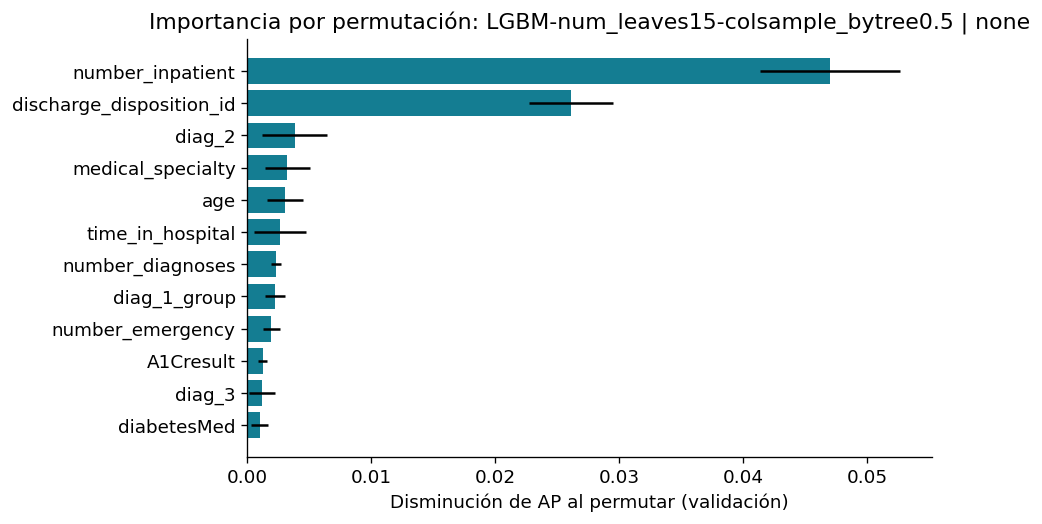

In [10]:
pos_weight = float((ytr == 0).sum() / (ytr == 1).sum())
def fit_chosen(Xfit, yfit, columns=None):
    columns = list(X.columns if columns is None else columns)
    nc, cc = [c for c in columns if c in num], [c for c in columns if c in cat]
    return ru.make_pipeline(chosen['kind'], chosen['strategy'], nc, cc, chosen['params'],
                            pos_weight, SEED).fit(Xfit[columns], yfit)
t0 = time.perf_counter()
best = fit_chosen(Xtr, ytr)
fit_seconds = time.perf_counter() - t0
p_val_raw = best.predict_proba(Xva)[:, 1]
negative = fit_chosen(Xtr, pd.Series(np.random.default_rng(SEED).permutation(ytr), index=ytr.index))
no_a1c_cols = [c for c in X.columns if c != 'A1Cresult']
no_a1c = fit_chosen(Xtr, ytr, no_a1c_cols)
diagnostics = {
    f'Elegido: {chosen_name}': metrics(yva, p_val_raw),
    'v1: logística': baseline_val['v1: logística'],
    'LACE (aprox.)': baseline_val['LACE (aprox.)'],
    'Etiquetas permutadas (control)': metrics(yva, negative.predict_proba(Xva)[:, 1]),
    'Elegido sin A1Cresult': metrics(yva, no_a1c.predict_proba(Xva[no_a1c_cols])[:, 1])}
print(f'Tiempo de ajuste del modelo elegido: {fit_seconds:.1f} s')
display(pd.DataFrame(diagnostics).T.round(4))
rng = np.random.default_rng(SEED)
sample = rng.choice(len(Xva), size=min(5000, len(Xva)), replace=False)
imp = permutation_importance(best, Xva.iloc[sample], yva.iloc[sample], scoring='average_precision',
                             n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({'feature': X.columns, 'drop_AP': imp.importances_mean,
                           'sd': imp.importances_std}).sort_values('drop_AP', ascending=False)
importance['rank'] = np.arange(1, len(importance)+1)
display(importance.head(12).round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
v = importance.head(12).iloc[::-1]
ax.barh(v.feature, v.drop_AP, xerr=v.sd, color='#147D92')
ax.set(xlabel='Disminución de AP al permutar (validación)', title=f'Importancia por permutación: {chosen_name}')
fig.tight_layout(); fig.savefig(OUT/'importancia.png', dpi=170); plt.show()

## 7. Recalibración en validación
El modelo de train queda congelado (`FrozenEstimator`) y se le ajusta un calibrador con validación. Platt (`sigmoid`) frente a isotónica se comparan con Brier fuera de fold (5 folds agrupados por paciente dentro de validación). El calibrador final se ajusta con toda la validación. Las predicciones fuera de fold se usan para las curvas de decisión de validación, así el calibrador no se evalúa con sus propios datos.

,método,Brier,media_predicha,prevalencia
0,sin recalibrar,0.09633,0.11373,0.11356
1,sigmoid,0.09628,0.11356,0.11356
2,isotonic,0.09640,0.11356,0.11356


Método de recalibración elegido: sigmoid


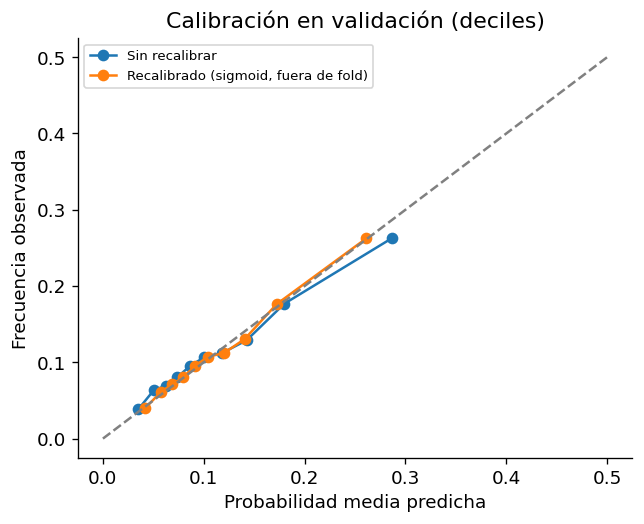

In [11]:
cal_method, cal_table, cal_oof = ru.choose_calibration(best, Xva, yva, groups.iloc[val_idx])
display(cal_table.round(5))
print('Método de recalibración elegido:', cal_method)
final = ru.fit_calibrator(best, Xva, yva, cal_method)
p_val = cal_oof[cal_method]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for lab, p in [('Sin recalibrar', p_val_raw), (f'Recalibrado ({cal_method}, fuera de fold)', p_val)]:
    fr, mp = calibration_curve(yva, p, n_bins=10, strategy='quantile')
    ax.plot(mp, fr, 'o-', label=lab)
lim = max(.5, float(np.quantile(p_val_raw, .99)))
ax.plot([0, lim], [0, lim], '--', color='gray')
ax.set(xlabel='Probabilidad media predicha', ylabel='Frecuencia observada', title='Calibración en validación (deciles)')
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT/'calibracion_validacion.png', dpi=170); plt.show()

## 8. Curva de decisión y justificación del cupo de 20 %
El **beneficio neto** a un umbral \(p_t\) es \(\text{TP}/n - \text{FP}/n \cdot p_t/(1-p_t)\). El umbral expresa cuánto vale intervenir: si una intervención de costo \(c\) evita una fracción \(e\) de los reingresos (costo \(R\)) en quien iba a reingresar, conviene intervenir cuando \(p \cdot e \cdot R > c\), es decir \(p_t = c/(e\,R)\).

Los parámetros siguientes son **supuestos ilustrativos editables**, no estimaciones locales: costo de un reingreso \(R = 100\) unidades; eficacia relativa \(e = 20\) %; llamado telefónico estructurado \(c = 1\); visita domiciliaria \(c = 5\). Las decisiones se toman en **validación**; el test solo confirma.

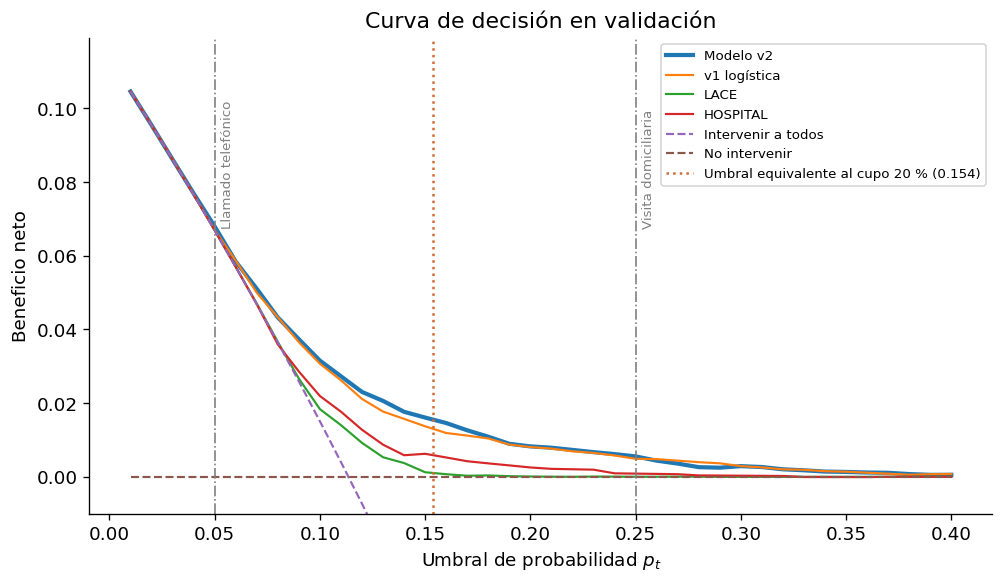

,escenario,costo_intervención,umbral_pt,fracción_seleccionada,recall,NB_modelo,NB_LACE,NB_intervenir_todos,altas_por_reingreso_captado
0,Llamado telefónico,1.00,0.0500,0.9074,0.9681,0.0680,0.0669,0.0669,8.2539
1,Visita domiciliaria,5.00,0.2500,0.0432,0.1318,0.0055,0.0000,-0.1819,2.8889
2,Cupo 20 % (implícito),3.08,0.1538,0.2000,0.3864,0.0155,0.0008,-0.0476,4.5580


,capacidad,selected,tp,precision,recall,lift,threshold
0,0.05,993,331,0.3333,0.1469,2.9354,0.2393
1,0.10,1985,521,0.2625,0.2311,2.3113,0.1959
2,0.20,3970,871,0.2194,0.3864,1.9320,0.1538
3,0.30,5955,1130,0.1898,0.5013,1.6710,0.1289
4,0.50,9925,1565,0.1577,0.6943,1.3886,0.0971


El cupo de 20 % equivale a intervenir con riesgo ≥ 0.154. Es coherente con una intervención que cueste hasta ≈3.1 % del costo de un reingreso si evita el 20% de los reingresos de quienes la reciben (relación daño:beneficio 0.182).


In [12]:
R_COST, EFFECT = 100.0, 0.20
SCENARIOS = {'Llamado telefónico': 1.0, 'Visita domiciliaria': 5.0}
thresholds = np.round(np.arange(0.01, 0.41, 0.01), 2)
p_lace_val, p_hosp_val = score_prob('LACE', val_idx), score_prob('HOSPITAL', val_idx)
p_v1_val = v1_lr.predict_proba(Xva[v1_cols])[:, 1]
dca_val = dcurves.dca(data=pd.DataFrame({'y': yva.values, 'Modelo v2': p_val, 'v1 logística': p_v1_val,
                                         'LACE': p_lace_val, 'HOSPITAL': p_hosp_val}),
                      outcome='y', modelnames=['Modelo v2', 'v1 logística', 'LACE', 'HOSPITAL'],
                      thresholds=thresholds)
q20 = top_metrics(yva, p_val, .20)
p20 = q20['threshold']
c_max = p20 * EFFECT * R_COST
fig, ax = plt.subplots(figsize=(8.5, 5))
for name, g in dca_val.groupby('model', sort=False):
    ax.plot(g.threshold, g.net_benefit, label={'all': 'Intervenir a todos', 'none': 'No intervenir'}.get(name, name),
            lw=2.5 if name == 'Modelo v2' else 1.3, ls='--' if name in ('all', 'none') else '-')
ax.axvline(p20, color='#D36B36', ls=':', label=f'Umbral equivalente al cupo 20 % ({p20:.3f})')
for s, c in SCENARIOS.items():
    ax.axvline(c/(EFFECT*R_COST), color='gray', ls='-.', lw=1)
    ax.text(c/(EFFECT*R_COST)+.003, yva.mean()*.6, s, rotation=90, fontsize=8, color='gray')
ax.set(ylim=(-0.01, yva.mean()*1.05), xlabel='Umbral de probabilidad $p_t$', ylabel='Beneficio neto',
       title='Curva de decisión en validación')
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT/'curva_decision_validacion.png', dpi=170); plt.show()

rows = []
for s, c in {**SCENARIOS, 'Cupo 20 % (implícito)': c_max}.items():
    pt = c/(EFFECT*R_COST)
    flag = p_val >= pt
    rows.append({'escenario': s, 'costo_intervención': round(c, 2), 'umbral_pt': round(pt, 4),
                 'fracción_seleccionada': flag.mean(), 'recall': (flag & (yva.values == 1)).sum()/yva.sum(),
                 'NB_modelo': ru.net_benefit(yva, p_val, pt), 'NB_LACE': ru.net_benefit(yva, p_lace_val, pt),
                 'NB_intervenir_todos': ru.net_benefit(yva, np.ones(len(yva)), pt),
                 'altas_por_reingreso_captado': 1/max(1e-9, (flag & (yva.values == 1)).sum()/max(1, flag.sum()))})
scenario_table = pd.DataFrame(rows)
display(scenario_table.round(4))
capacity_val = pd.DataFrame([{'capacidad': q, **top_metrics(yva, p_val, q)} for q in [.05, .10, .20, .30, .50]])
display(capacity_val[['capacidad', 'selected', 'tp', 'precision', 'recall', 'lift', 'threshold']].round(4))
print(f'El cupo de 20 % equivale a intervenir con riesgo ≥ {p20:.3f}. Es coherente con una intervención '
      f'que cueste hasta ≈{c_max:.1f} % del costo de un reingreso si evita el {EFFECT:.0%} de los reingresos '
      f'de quienes la reciben (relación daño:beneficio {p20/(1-p20):.3f}).')

**Lectura de la curva de decisión.**
- Para una intervención muy barata (llamado, \(p_t = 0{,}05\)), el modelo casi no aporta frente a **intervenir a todos**: seleccionaría el 91 % de las altas. En ese escenario conviene llamar a todos.
- El cupo de 20 % equivale a un umbral de ≈0,15. Con los supuestos de la celda, se justifica si la intervención cuesta hasta ≈3 % de un reingreso y evita el 20 % de los reingresos de quienes la reciben, por ejemplo un llamado estructurado de enfermería más un turno temprano. Allí el beneficio neto del modelo (0,0155) supera claramente a LACE (0,0008) y a intervenir a todos (negativo).
- Para una visita domiciliaria (\(p_t = 0{,}25\)) el modelo seleccionaría solo ≈4 % de las altas, con ≈3 altas visitadas por reingreso captado. El cupo debería achicarse en lugar de mantenerse en 20 %.
- El modelo v2 y la logística v1 casi se superponen: la mejora de v2 es pequeña en términos de decisión.

## 9. Evaluación sobre test (evidencia secundaria)
El modelo recalibrado queda congelado. Se compara contra la logística de la v1 (reentrenada con el mismo código y la misma partición), LACE, HOSPITAL, utilización previa y prevalencia. Las diferencias se estiman con bootstrap pareado por paciente. Recordatorio: este test ya fue consultado en la v1.

In [13]:
test_probs = {'Modelo v2': final.predict_proba(Xte)[:, 1],
              'Modelo v2 sin recalibrar': best.predict_proba(Xte)[:, 1],
              'v1 logística': v1_lr.predict_proba(Xte[v1_cols])[:, 1],
              'LACE (aprox.)': score_prob('LACE', test_idx),
              'HOSPITAL (parcial)': score_prob('HOSPITAL', test_idx),
              'Solo utilización previa (LR)': only_history.predict_proba(Xte[history])[:, 1],
              'Prevalencia constante': np.full(len(yte), ytr.mean())}
test_scores = {n: metrics(yte, p) for n, p in test_probs.items()}
test_table = pd.DataFrame(test_scores).T
pbest = test_probs['Modelo v2']
print(f'Prevalencia test: {yte.mean():.2%}; episodios: {len(yte):,}; positivos: {yte.sum():,}')
display(test_table.round(4))
capacity = pd.DataFrame([{'capacidad': q, **top_metrics(yte, pbest, q)} for q in [.05, .10, .20, .30, .50]])
display(capacity.round(4))
operating = top_metrics(yte, pbest, .20)
fixed = pbest >= p20
print(f'Top 20 %: {operating}')
print(f'Con el umbral fijado en validación ({p20:.3f}) se seleccionaría el {fixed.mean():.1%} del test.')

Prevalencia test: 11.43%; episodios: 19,771; positivos: 2,259


,AUROC,AP,Brier,Precision@20,Recall@20,Lift@20
Modelo v2,0.6791,0.2235,0.0963,0.2230,0.3904,1.9518
Modelo v2 sin recalibrar,0.6791,0.2235,0.0964,0.2230,0.3904,1.9518
v1 logística,0.6716,0.2171,0.0970,0.2225,0.3896,1.9474
LACE (aprox.),0.5798,0.1445,0.1003,0.1638,0.2869,1.4340
HOSPITAL (parcial),0.5952,0.1570,0.0997,0.1727,0.3023,1.5114
Solo utilización previa (LR),0.6133,0.1837,0.0988,0.1995,0.3493,1.7460
Prevalencia constante,0.5000,0.1143,0.1012,0.1214,0.2125,1.0622


,capacidad,selected,tp,fp,fn,precision,recall,lift,fraction,threshold
0,0.05,989,322,667,1937,0.3256,0.1425,2.8495,0.05,0.2423
1,0.10,1978,541,1437,1718,0.2735,0.2395,2.3938,0.10,0.1962
2,0.20,3955,882,3073,1377,0.2230,0.3904,1.9518,0.20,0.1546
3,0.30,5932,1190,4742,1069,0.2006,0.5268,1.7557,0.30,0.1305
4,0.50,9886,1645,8241,614,0.1664,0.7282,1.4563,0.50,0.0979


Top 20 %: {'selected': 3955, 'tp': 882, 'fp': 3073, 'fn': 1377, 'precision': 0.22300884955752212, 'recall': 0.3904382470119522, 'lift': 1.9517963544053871, 'fraction': 0.20004046330484043, 'threshold': 0.15455980065617347}
Con el umbral fijado en validación (0.154) se seleccionaría el 20.2% del test.


In [14]:
gt = groups.iloc[test_idx].to_numpy()
boot_models = ['Modelo v2', 'v1 logística', 'LACE (aprox.)', 'HOSPITAL (parcial)']
boot = ru.grouped_bootstrap(yte, {k: test_probs[k] for k in boot_models}, gt, n_boot=300, seed=SEED+2,
                            pairs=[('Modelo v2', 'LACE (aprox.)'), ('Modelo v2', 'HOSPITAL (parcial)'),
                                   ('Modelo v2', 'v1 logística')])
ci_all = ru.bootstrap_ci(boot)
ci = ci_all.loc['Modelo v2']
display(ci.round(4))
diffs = ci_all.loc[[i for i in ci_all.index.get_level_values(0).unique() if '−' in i]]
display(diffs.round(4))
ap_vs_lace_lo = ci_all.loc[('Modelo v2 − LACE (aprox.)', 'AP'), 'IC95_inferior']
criteria = {
    'AP/prevalencia ≥ 1,5': test_scores['Modelo v2']['AP']/yte.mean() >= 1.5,
    'Lift@20 ≥ 1,5': operating['lift'] >= 1.5,
    'IC95 inf. (AP − prevalencia) > 0': ci.loc['AP_minus_prevalence', 'IC95_inferior'] > 0,
    'IC95 inf. AUROC > 0,5': ci.loc['AUROC', 'IC95_inferior'] > 0.5,
    'IC95 inf. (AP v2 − AP LACE) > 0': ap_vs_lace_lo > 0}
display(pd.Series(criteria, name='cumple').to_frame())
feasible = bool(all(criteria.values()))
print('DECISIÓN EXPLORATORIA (secundaria):', 'CONTINUAR' if feasible else 'REVISAR O CAMBIAR ENFOQUE')

,IC95_inferior,IC95_superior
metrica,,
AP,0.2087,0.2415
AP_minus_prevalence,0.0968,0.1257
AUROC,0.6673,0.6917
Brier,0.0927,0.1005
Lift@20,1.8622,2.0541
Precision@20,0.2079,0.2399
Recall@20,0.3725,0.4109


IC95_inferior  IC95_superior
modelo                         metrica                                
Modelo v2 − HOSPITAL (parcial) AP                0.0553         0.0771
                               AUROC             0.0708         0.0954
                               Brier            -0.0039        -0.0026
                               Lift@20           0.3505         0.5615
                               Recall@20         0.0701         0.1123
Modelo v2 − LACE (aprox.)      AP                0.0671         0.0934
                               AUROC             0.0870         0.1153
                               Brier            -0.0048        -0.0033
                               Lift@20           0.4022         0.6473
                               Recall@20         0.0805         0.1295
Modelo v2 − v1 logística       AP                0.0005         0.0135
                               AUROC             0.0025         0.0128
                               Brier            -0.0010        -0.0003
                               Lift@20          -0.0551         0.0875
                               Recall@20        -0.0110         0.0175

,cumple
"AP/prevalencia ≥ 1,5",True
"Lift@20 ≥ 1,5",True
IC95 inf. (AP − prevalencia) > 0,True
"IC95 inf. AUROC > 0,5",True
IC95 inf. (AP v2 − AP LACE) > 0,True


DECISIÓN EXPLORATORIA (secundaria): CONTINUAR


**Lectura de test (secundaria; este test ya se había consultado en la v1).**
- **Desempeño:** AUROC 0,679 (IC95 0,667–0,692), AP 0,224 (0,209–0,242) con prevalencia 0,114, lift@20 % 1,95. Se cumplen todos los criterios de continuidad, incluido el nuevo de valor agregado frente a LACE.
- **Frente a la v1:** la diferencia pareada con la logística es pequeña pero con IC por encima de cero (ΔAP +0,0005 a +0,0135; ΔAUROC +0,003 a +0,013). En el punto operativo no cambia: precision@20 % 22,3 % frente a 22,2 %. De cada 9 altas priorizadas, ≈7 no reingresan, igual que en la v1.
- **Frente a los scores clínicos:** el modelo supera claramente a LACE (ΔAP +0,067 a +0,093) y a HOSPITAL (+0,055 a +0,077). Pero LACE (AUROC 0,58) y HOSPITAL (0,60) rinden aquí menos que en la literatura (≈0,65–0,72), porque son aproximaciones: Charlson con solo 3 diagnósticos, guardias del último año en vez de 6 meses, y sin hemoglobina ni sodio. La comparación justa es la de MIMIC-IV, donde se calculan completos.
- **Calibración:** LightGBM sin remuestreo ya estaba bien calibrado, y la recalibración Platt casi no lo cambia (Brier 0,0964 → 0,0963). El umbral fijado en validación selecciona 20,2 % del test, así que el cupo es estable.

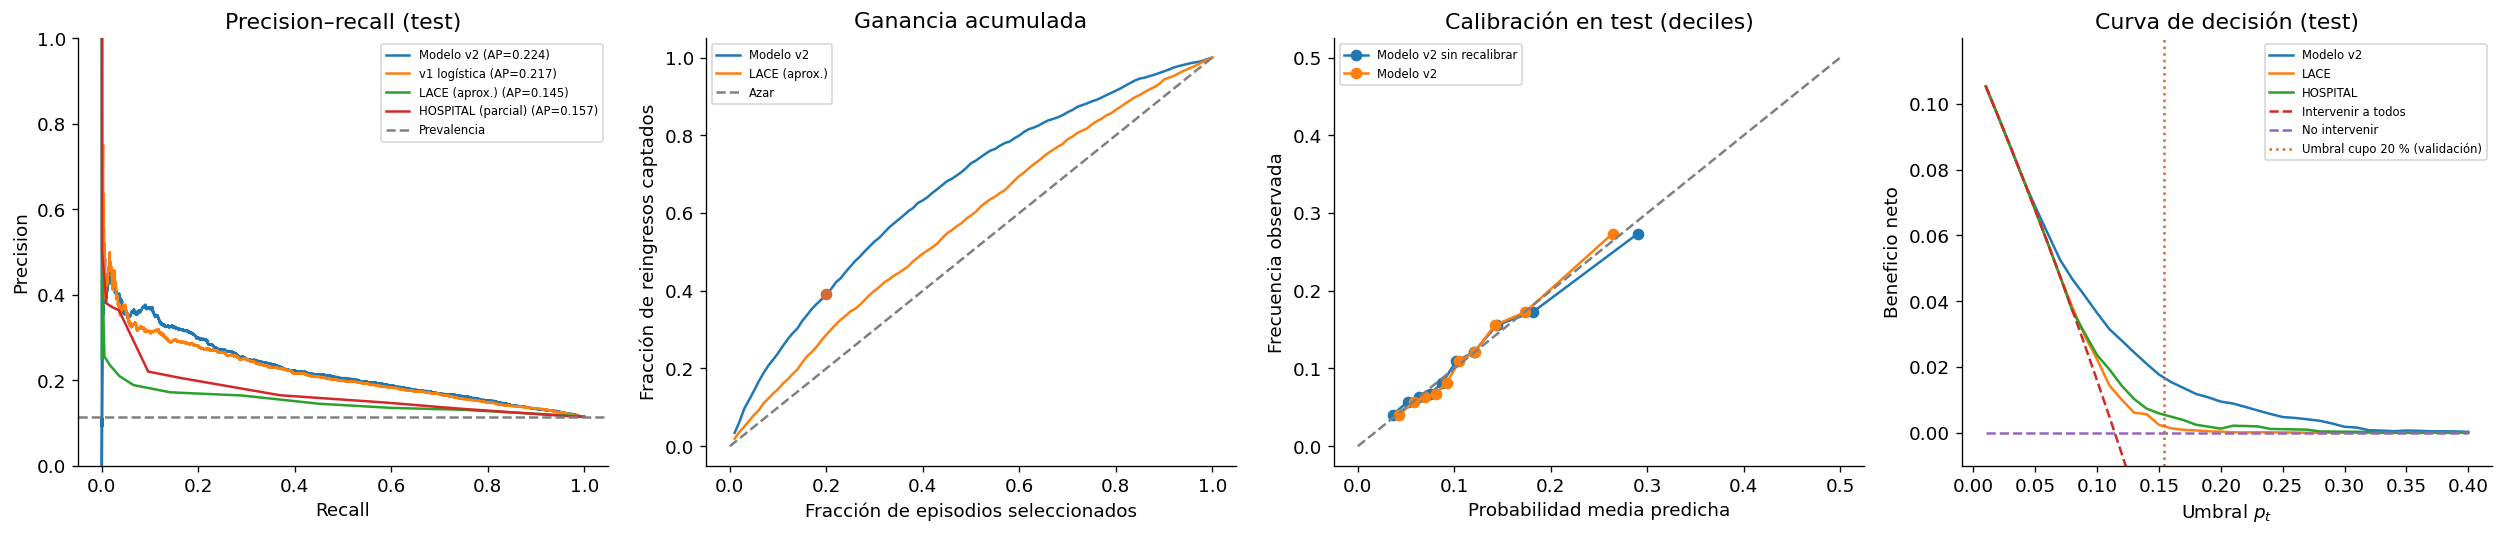

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for name in ['Modelo v2', 'v1 logística', 'LACE (aprox.)', 'HOSPITAL (parcial)']:
    pr, rec, _ = precision_recall_curve(yte, test_probs[name])
    axes[0].plot(rec, pr, label=f"{name} (AP={test_scores[name]['AP']:.3f})")
axes[0].axhline(yte.mean(), color='gray', ls='--', label='Prevalencia')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Precision–recall (test)', ylim=(0, 1)); axes[0].legend(fontsize=7)
qgrid = np.linspace(.01, 1, 100)
for name in ['Modelo v2', 'LACE (aprox.)']:
    axes[1].plot(qgrid, [top_metrics(yte, test_probs[name], q)['recall'] for q in qgrid], label=name)
gains = [top_metrics(yte, pbest, q)['recall'] for q in qgrid]
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Azar')
axes[1].scatter([.20], [operating['recall']], color='#D36B36', zorder=4)
axes[1].set(xlabel='Fracción de episodios seleccionados', ylabel='Fracción de reingresos captados', title='Ganancia acumulada')
axes[1].legend(fontsize=7)
for lab in ['Modelo v2 sin recalibrar', 'Modelo v2']:
    fr, mp = calibration_curve(yte, test_probs[lab], n_bins=10, strategy='quantile')
    axes[2].plot(mp, fr, 'o-', label=lab)
axes[2].plot([0, .5], [0, .5], '--', color='gray')
axes[2].set(xlabel='Probabilidad media predicha', ylabel='Frecuencia observada', title='Calibración en test (deciles)')
axes[2].legend(fontsize=7)
dca_test = dcurves.dca(data=pd.DataFrame({'y': yte.values, 'Modelo v2': pbest, 'LACE': test_probs['LACE (aprox.)'],
                                          'HOSPITAL': test_probs['HOSPITAL (parcial)']}),
                       outcome='y', modelnames=['Modelo v2', 'LACE', 'HOSPITAL'], thresholds=thresholds)
for name, g in dca_test.groupby('model', sort=False):
    axes[3].plot(g.threshold, g.net_benefit, label={'all': 'Intervenir a todos', 'none': 'No intervenir'}.get(name, name),
                 ls='--' if name in ('all', 'none') else '-')
axes[3].axvline(p20, color='#D36B36', ls=':', label='Umbral cupo 20 % (validación)')
axes[3].set(ylim=(-0.01, yte.mean()*1.05), xlabel='Umbral $p_t$', ylabel='Beneficio neto', title='Curva de decisión (test)')
axes[3].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT/'evaluacion_test.png', dpi=170); plt.show()

## 10. Subgrupos con intervalos y rol de HbA1c
Métricas del modelo congelado en test por sexo, edad, resultado de HbA1c y alta a domicilio (códigos 1, 6, 8), con IC95 % por bootstrap de pacientes (200 remuestreos). Son descriptivas: diferencias puntuales no establecen inequidad ni equidad.

**HbA1c.** Strack et al. (2014) analizaron justamente si medir HbA1c se asocia con menor reingreso, y encontraron que la asociación depende del diagnóstico principal y de si se cambió la medicación. Aquí se describe la tasa de reingreso por `A1Cresult`, su interacción con `change`, su importancia en el modelo y la ablación de la sección 6.

,variable,grupo,n,prevalencia,AUROC,AUROC_lo,AUROC_hi,AP,AP_lo,AP_hi,pred_media
0,gender,Female,10470,0.115,0.691,0.676,0.708,0.229,0.212,0.249,0.115
1,gender,Male,9301,0.114,0.665,0.643,0.680,0.218,0.189,0.244,0.114
2,age,[20-30),336,0.134,0.762,0.675,0.842,0.297,0.188,0.434,0.137
3,age,[30-40),710,0.108,0.727,0.657,0.774,0.248,0.179,0.347,0.110
4,age,[40-50),2007,0.107,0.721,0.678,0.757,0.239,0.184,0.301,0.111
5,age,[50-60),3378,0.103,0.720,0.680,0.757,0.260,0.213,0.320,0.101
6,age,[60-70),4472,0.116,0.661,0.630,0.683,0.217,0.188,0.247,0.112
7,age,[70-80),5025,0.119,0.671,0.648,0.694,0.245,0.215,0.283,0.121
8,age,[80-90),3350,0.118,0.628,0.597,0.653,0.176,0.151,0.206,0.124
9,age,[90-100),493,0.124,0.560,0.483,0.639,0.181,0.123,0.293,0.122


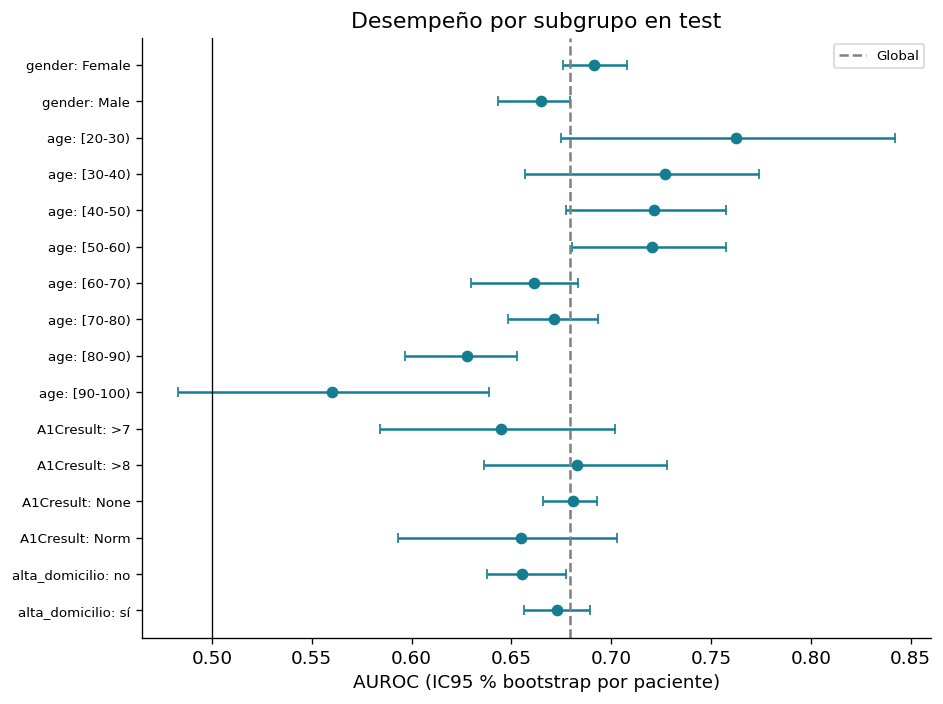

In [16]:
ct = cohort.iloc[test_idx].reset_index(drop=True)
ct['alta_domicilio'] = np.where(ct.discharge_disposition_id.isin([1, 6, 8]), 'sí', 'no')
ya = yte.to_numpy()
subgroups = []
for col in ['gender', 'age', 'A1Cresult', 'alta_domicilio']:
    for value in sorted(ct[col].unique()):
        mask = ct[col].eq(value).to_numpy()
        if mask.sum() < 200 or ya[mask].sum() < 20:
            continue
        b = ru.grouped_bootstrap(ya[mask], {'m': pbest[mask]}, gt[mask], n_boot=200, seed=SEED+3)
        q = b[b.metrica.isin(['AUROC', 'AP'])].groupby('metrica').valor.quantile([.025, .975]).unstack()
        subgroups.append({'variable': col, 'grupo': value, 'n': int(mask.sum()), 'prevalencia': ya[mask].mean(),
                          'AUROC': roc_auc_score(ya[mask], pbest[mask]), 'AUROC_lo': q.loc['AUROC', .025],
                          'AUROC_hi': q.loc['AUROC', .975], 'AP': average_precision_score(ya[mask], pbest[mask]),
                          'AP_lo': q.loc['AP', .025], 'AP_hi': q.loc['AP', .975],
                          'pred_media': pbest[mask].mean()})
subgroups = pd.DataFrame(subgroups)
display(subgroups.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
lab = subgroups.variable + ': ' + subgroups.grupo.astype(str)
ax.errorbar(subgroups.AUROC, range(len(subgroups)), xerr=[subgroups.AUROC-subgroups.AUROC_lo, subgroups.AUROC_hi-subgroups.AUROC],
            fmt='o', color='#147D92', capsize=3)
ax.axvline(test_scores['Modelo v2']['AUROC'], color='gray', ls='--', label='Global')
ax.axvline(.5, color='k', lw=.8)
ax.set_yticks(range(len(subgroups)), lab, fontsize=8); ax.invert_yaxis()
ax.set(xlabel='AUROC (IC95 % bootstrap por paciente)', title='Desempeño por subgrupo en test'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'subgrupos.png', dpi=170); plt.show()

Tasa de reingreso <30 días por resultado de HbA1c (desarrollo, train + validación):


,episodios,reingresos,tasa,IC95_lo,IC95_hi,fracción_episodios
A1Cresult,,,,,,
>7,2967,300,0.1011,0.0908,0.1125,0.0377
>8,6214,639,0.1028,0.0955,0.1106,0.0789
None,65673,7697,0.1172,0.1148,0.1197,0.8343
Norm,3865,376,0.0973,0.0883,0.1070,0.0491


Interacción medición de HbA1c × cambio de medicación (tasa y n):


mean           size       
change         Ch      No     Ch     No
medido                                 
medida     0.1042  0.0964   7339   5707
no medida  0.1250  0.1110  29235  36438

A1Cresult: puesto 10 de 45 en importancia por permutación (caída de AP 0.0012 ± 0.0003). Ablación en validación: ΔAP = +0.0031.


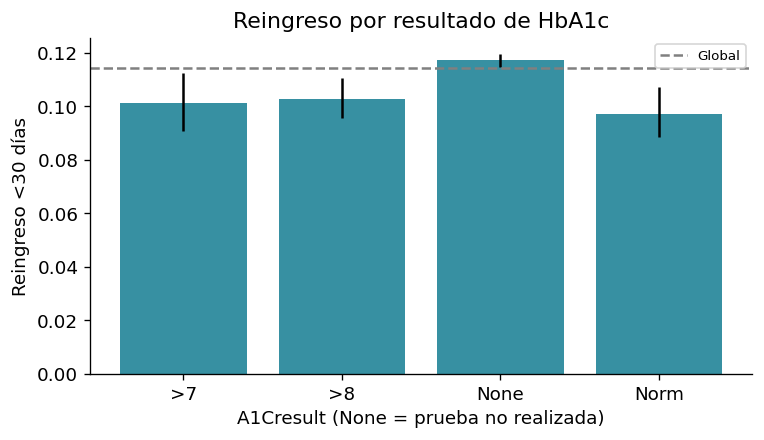

In [17]:
cd = cohort.iloc[dev_idx].assign(y=y.iloc[dev_idx].values)
a1c = cd.groupby('A1Cresult').y.agg(['size', 'sum', 'mean'])
a1c['IC95_lo'], a1c['IC95_hi'] = ru.wilson_ci(a1c['sum'], a1c['size'])
a1c['fracción_episodios'] = a1c['size']/a1c['size'].sum()
print('Tasa de reingreso <30 días por resultado de HbA1c (desarrollo, train + validación):')
display(a1c.rename(columns={'size': 'episodios', 'sum': 'reingresos', 'mean': 'tasa'}).round(4))
inter = cd.assign(medido=np.where(cd.A1Cresult.eq('None'), 'no medida', 'medida')).pivot_table(
    index='medido', columns='change', values='y', aggfunc=['mean', 'size'])
print('Interacción medición de HbA1c × cambio de medicación (tasa y n):'); display(inter.round(4))
a1c_rank = importance.set_index('feature').loc['A1Cresult']
abl = diagnostics['Elegido sin A1Cresult']['AP'] - diagnostics[f'Elegido: {chosen_name}']['AP']
print(f"A1Cresult: puesto {int(a1c_rank['rank'])} de {len(importance)} en importancia por permutación "
      f"(caída de AP {a1c_rank.drop_AP:.4f} ± {a1c_rank.sd:.4f}). Ablación en validación: ΔAP = {abl:+.4f}.")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(a1c.index, a1c['mean'], color='#147D92', alpha=.85)
ax.errorbar(a1c.index, a1c['mean'], yerr=[a1c['mean']-a1c.IC95_lo, a1c.IC95_hi-a1c['mean']], fmt='none', color='k')
ax.axhline(cd.y.mean(), ls='--', color='gray', label='Global')
ax.set(xlabel='A1Cresult (None = prueba no realizada)', ylabel='Reingreso <30 días', title='Reingreso por resultado de HbA1c')
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT/'hba1c.png', dpi=170); plt.show()

**Rol de HbA1c.**
- **Medición:** en el 83 % de las internaciones no se midió HbA1c. Esos episodios reingresan más (11,7 %) que los que tuvieron HbA1c medida, sea cual sea el resultado: 9,7 % normal, 10,1 % entre 7 y 8 %, 10,3 % mayor a 8 %, con IC que no se superponen con el grupo no medido. Esto concuerda con Strack et al. (2014): lo que se asocia con menos reingreso es **haber medido** (un marcador del proceso de atención y de la atención a la diabetes), más que el valor de HbA1c. La tasa más baja corresponde a "medida y sin cambio de medicación" (9,6 %), aunque Strack mostró que la asociación depende del diagnóstico principal.
- **En el modelo:** `A1Cresult` queda 10.º en importancia por permutación (caída de AP 0,0012), pero reentrenar sin ella **no empeora** la AP de validación (+0,003). Su información es débil y redundante con otras variables de proceso, como especialidad, cantidad de pruebas y medicación.
- **Para implementar:** que "no medida" signifique algo depende de las prácticas locales de laboratorio, lo que la vuelve una variable poco transportable. Conviene monitorearla o excluirla, y no interpretarla como control glucémico.

## 11. Interoperabilidad: diccionario de datos, disponibilidad al alta y terminologías
Para llevar el modelo a un hospital local hay que saber **de qué sistema sale cada variable, si existe el día del alta y a qué terminología estándar se mapea**. La tabla es una propuesta para validar con el área de estadística y sistemas de un hospital; las columnas de disponibilidad son hipótesis, no relevamiento.

- **Diagnósticos:** UCI usa CIE-9-CM. En Argentina los egresos hospitalarios se codifican con **CIE-10 de la OMS** (DEIS), no con CIE-10-CM. El mapeo a nivel de código puede partir de las General Equivalence Mappings (GEMs) de CMS (CIE-9-CM → CIE-10-CM) y luego truncar a 3–4 caracteres OMS; para problemas clínicos en la HCE, SNOMED CT (con el mapa SNOMED CT → CIE-10 de SNOMED International).
- **Laboratorio:** LOINC. **Medicamentos:** ATC (y SNOMED CT para productos). **Datos administrativos:** HL7 FHIR `Encounter` (tipo de admisión, origen, destino al alta).

In [18]:
ATC = {'metformin': 'A10BA02', 'repaglinide': 'A10BX02', 'nateglinide': 'A10BX03', 'chlorpropamide': 'A10BB02',
       'glimepiride': 'A10BB12', 'acetohexamide': 'A10BB31', 'glipizide': 'A10BB07', 'glyburide': 'A10BB01',
       'tolbutamide': 'A10BB03', 'pioglitazone': 'A10BG03', 'rosiglitazone': 'A10BG02', 'acarbose': 'A10BF01',
       'miglitol': 'A10BF02', 'troglitazone': 'A10BG01', 'tolazamide': 'A10BB05', 'insulin': 'A10A',
       'glyburide-metformin': 'A10BD02', 'glipizide-metformin': 'A10BD (combinación)',
       'glimepiride-pioglitazone': 'A10BD06', 'metformin-rosiglitazone': 'A10BD03',
       'metformin-pioglitazone': 'A10BD05'}
D = {
 'gender': ('Sexo registrado', 'ADT / admisión', 'Sí (ingreso)', 'HL7 FHIR administrative-gender'),
 'age': ('Edad en decenios', 'ADT / padrón', 'Sí (ingreso)', 'Fecha de nacimiento → edad'),
 'admission_type_id': ('Tipo de admisión (urgencia, electiva…)', 'ADT', 'Sí (ingreso)', 'FHIR Encounter.priority / SNOMED CT'),
 'discharge_disposition_id': ('Destino al alta', 'Sistema de egresos / HCE', 'Sí, si se registra antes de emitir el score', 'FHIR Encounter.hospitalization.dischargeDisposition'),
 'admission_source_id': ('Origen de la admisión', 'ADT', 'Sí (ingreso)', 'FHIR Encounter.hospitalization.admitSource'),
 'time_in_hospital': ('Días de internación', 'ADT / egresos', 'Sí (al alta)', '—'),
 'medical_specialty': ('Especialidad del médico tratante', 'HCE / ADT', 'Sí', 'SNOMED CT (especialidad clínica)'),
 'num_lab_procedures': ('Cantidad de pruebas de laboratorio', 'LIS (laboratorio)', 'Sí (conteo); resultados pendientes posibles', 'LOINC'),
 'num_procedures': ('Procedimientos no de laboratorio', 'HCE / facturación', 'Parcial: la codificación suele completarse después', 'CIE-9-CM vol. 3 → CIE-10-PCS / SNOMED CT'),
 'num_medications': ('Medicamentos distintos administrados', 'Farmacia / prescripción electrónica', 'Sí', 'ATC / SNOMED CT'),
 'number_outpatient': ('Consultas ambulatorias año previo', 'HCE de la red / turnos', 'Sí, solo dentro de la red', '—'),
 'number_emergency': ('Visitas a guardia año previo', 'Sistema de guardia', 'Sí, solo dentro de la red', '—'),
 'number_inpatient': ('Internaciones año previo', 'Sistema de egresos', 'Sí, solo dentro de la red', '—'),
 'diag_1': ('Diagnóstico principal (CIE-9-CM)', 'Codificación de egresos', 'Diferida: suele codificarse días después del alta', 'CIE-10 OMS (vía GEMs) / SNOMED CT'),
 'diag_2': ('Diagnóstico secundario', 'Codificación de egresos', 'Diferida', 'CIE-10 OMS / SNOMED CT'),
 'diag_3': ('Diagnóstico secundario adicional', 'Codificación de egresos', 'Diferida', 'CIE-10 OMS / SNOMED CT'),
 'number_diagnoses': ('Cantidad de diagnósticos codificados', 'Codificación de egresos', 'Diferida', '—'),
 'max_glu_serum': ('Glucemia sérica (categorizada)', 'LIS', 'Sí si se midió', 'LOINC 2345-7'),
 'A1Cresult': ('HbA1c (categorizada; None = no medida)', 'LIS', 'Sí si se midió; el resultado puede llegar tarde', 'LOINC 4548-4'),
 'change': ('Cambio de medicación antidiabética', 'Farmacia / HCE', 'Sí (conciliación al alta)', 'ATC A10'),
 'diabetesMed': ('Prescripción de antidiabéticos', 'Farmacia', 'Sí', 'ATC A10'),
}
for k in (1, 2, 3):
    D[f'diag_{k}_group'] = (f'Grupo diagnóstico de diag_{k} (Strack)', 'Derivada', 'Diferida (depende de diag)', 'Capítulos CIE-10')
rows = []
for c in X.columns:
    if c in D:
        desc, src, avail, std = D[c]
    elif c in ATC:
        desc, src, avail, std = (f'{c}: dosis (No/Steady/Up/Down)', 'Farmacia / prescripción', 'Sí', f'ATC {ATC[c]}')
    else:
        desc, src, avail, std = ('', '', 'A relevar', '')
    rows.append({'variable': c, 'tipo': 'numérica' if c in num else 'categórica', 'descripción': desc,
                 'sistema_origen': src, 'disponible_al_alta': avail, 'estándar_destino': std,
                 'faltante_train': float(Xtr[c].isna().mean()),
                 'rank_importancia': int(importance.set_index('feature').loc[c, 'rank'])})
data_dictionary = pd.DataFrame(rows)
data_dictionary.to_csv(OUT/'diccionario_datos.csv', index=False)
display(data_dictionary)
deferred = data_dictionary[data_dictionary.disponible_al_alta.str.startswith(('Diferida', 'Parcial'))]
print(f'{len(deferred)} variables dependen de codificación posterior al alta; '
      f'{(deferred.rank_importancia <= 10).sum()} están entre las 10 más importantes.')
icd_map = pd.DataFrame([
    ('Circulatory', '390–459, 785', 'I00–I99, R00–R03'), ('Respiratory', '460–519, 786', 'J00–J99, R04–R09'),
    ('Digestive', '520–579, 787', 'K00–K93, R10–R19'), ('Diabetes', '250.xx', 'E10–E14 (OMS) / E08–E13 (CM)'),
    ('Injury', '800–999', 'S00–T98'), ('Musculoskeletal', '710–739', 'M00–M99'),
    ('Genitourinary', '580–629, 788', 'N00–N99, R30–R39'), ('Neoplasms', '140–239', 'C00–D48'),
    ('Other', 'resto, V y E', 'resto; V → Z00–Z99; E → V01–Y98')], columns=['grupo', 'CIE-9-CM', 'CIE-10 (aprox. por capítulo)'])
display(icd_map)
icd_map.to_csv(OUT/'mapeo_cie9_cie10_grupos.csv', index=False)

,variable,tipo,descripción,sistema_origen,disponible_al_alta,estándar_destino,faltante_train,rank_importancia
0,gender,categórica,Sexo registrado,ADT / admisión,Sí (ingreso),HL7 FHIR administrative-gender,0.000000,18
1,age,categórica,Edad en decenios,ADT / padrón,Sí (ingreso),Fecha de nacimiento → edad,0.000000,5
2,admission_type_id,categórica,"Tipo de admisión (urgencia, electiva…)",ADT,Sí (ingreso),FHIR Encounter.priority / SNOMED CT,0.000000,14
3,discharge_disposition_id,categórica,Destino al alta,Sistema de egresos / HCE,"Sí, si se registra antes de emitir el score",FHIR Encounter.hospitalization.dischargeDispos...,0.000000,2
4,admission_source_id,categórica,Origen de la admisión,ADT,Sí (ingreso),FHIR Encounter.hospitalization.admitSource,0.000000,36
5,time_in_hospital,numérica,Días de internación,ADT / egresos,Sí (al alta),—,0.000000,6
6,medical_specialty,categórica,Especialidad del médico tratante,HCE / ADT,Sí,SNOMED CT (especialidad clínica),0.490505,4
7,num_lab_procedures,numérica,Cantidad de pruebas de laboratorio,LIS (laboratorio),Sí (conteo); resultados pendientes posibles,LOINC,0.000000,44
8,num_procedures,numérica,Procedimientos no de laboratorio,HCE / facturación,Parcial: la codificación suele completarse des...,CIE-9-CM vol. 3 → CIE-10-PCS / SNOMED CT,0.000000,19
9,num_medications,numérica,Medicamentos distintos administrados,Farmacia / prescripción electrónica,Sí,ATC / SNOMED CT,0.000000,16


8 variables dependen de codificación posterior al alta; 3 están entre las 10 más importantes.


,grupo,CIE-9-CM,CIE-10 (aprox. por capítulo)
0,Circulatory,"390–459, 785","I00–I99, R00–R03"
1,Respiratory,"460–519, 786","J00–J99, R04–R09"
2,Digestive,"520–579, 787","K00–K93, R10–R19"
3,Diabetes,250.xx,E10–E14 (OMS) / E08–E13 (CM)
4,Injury,800–999,S00–T98
5,Musculoskeletal,710–739,M00–M99
6,Genitourinary,"580–629, 788","N00–N99, R30–R39"
7,Neoplasms,140–239,C00–D48
8,Other,"resto, V y E",resto; V → Z00–Z99; E → V01–Y98


## 12. Ficha del modelo (TRIPOD+AI) y riesgo de sesgo (PROBAST)
La ficha se genera con los resultados de esta ejecución y se guarda en `output/v2/ficha_modelo.md`.

In [19]:
m = test_scores['Modelo v2']
auc_lo, auc_hi = ci.loc['AUROC', 'IC95_inferior'], ci.loc['AUROC', 'IC95_superior']
ap_lo, ap_hi = ci.loc['AP', 'IC95_inferior'], ci.loc['AP', 'IC95_superior']
ap_lace, ap_hosp, ap_v1 = (test_scores[k]['AP'] for k in ['LACE (aprox.)', 'HOSPITAL (parcial)', 'v1 logística'])
auc, ap, brier, lift = m['AUROC'], m['AP'], m['Brier'], m['Lift@20']
card = f'''
### Ficha del modelo: reingreso <30 días, v2 (TRIPOD+AI)

| Ítem | Contenido |
|---|---|
| Uso previsto | Priorizar seguimiento posalta (por episodio) en adultos con diabetes. Apoyo a la decisión, no diagnóstico. Investigación académica; no validado para uso clínico. |
| Fuente de datos | UCI Diabetes 130-US Hospitals 1999–2008 (Health Facts), SHA-256 `{sha256[:16]}…`. 130 hospitales de EE. UU. |
| Participantes | {len(cohort):,} internaciones de {groups.nunique():,} pacientes; ≥20 años; sin fallecimiento/hospice. Prevalencia {y.mean():.2%}. |
| Outcome | Reingreso registrado <30 días, cualquier causa, dentro de la red de datos. |
| Predictores | {X.shape[1]} variables al alta (sin raza ni financiador). Ver `diccionario_datos.csv`. |
| Tamaño muestral | Train {len(train_idx):,} ({int(ytr.sum()):,} eventos); validación {len(val_idx):,}; test {len(test_idx):,}. |
| Faltantes | Mediana (numéricas) y categoría "Missing" (categóricas), ajustadas en cada fold de train. |
| Desarrollo | Grilla LR/HGB/XGBoost/LightGBM × desbalance; CV 5×3 agrupada por paciente; regla de 1 EE. Elegido: **{chosen_name.replace('|', chr(92) + '|')}**. Recalibración {cal_method} en validación. |
| Desempeño (test, secundario) | AUROC {auc:.3f} (IC95 {auc_lo:.3f}–{auc_hi:.3f}); AP {ap:.3f} ({ap_lo:.3f}–{ap_hi:.3f}); Brier {brier:.4f}; lift@20 % {lift:.2f}. |
| Comparadores | LACE aprox. AP {ap_lace:.3f}; HOSPITAL parcial AP {ap_hosp:.3f}; v1 LR AP {ap_v1:.3f}. |
| Punto operativo | Cupo 20 % ≡ umbral {p20:.3f}; coherente con intervenciones de costo ≤ {c_max:.1f} % de un reingreso (si evitan el {EFFECT:.0%}). |
| Equidad | Métricas por sexo, edad, HbA1c y destino con IC95 % (sección 10). Raza excluida del predictor, lo que no garantiza equidad. |
| Validación | Interna (partición por paciente + CV repetida). **Sin validación temporal ni externa** en UCI; ver notebook MIMIC-IV. |
| Código y registro | `reingresos_utils.py`, este notebook y corridas en MLflow (`mlruns/`). Semilla {SEED}. |
'''
probast = pd.DataFrame([
    ('Participantes', 'Moderado', 'Alta', 'Base retrospectiva con criterios del dataset (diabetes, 1–14 días, laboratorio y medicación). Población de EE. UU. 1999–2008.'),
    ('Predictores', 'Incierto', 'Alta', 'Definición uniforme, pero la disponibilidad al alta no fue verificada; diagnósticos codificados después del alta.'),
    ('Outcome', 'Alto', 'Moderada', 'Reingresos fuera de la red no observados: "NO" puede ser ausencia de registro. Sin etiqueta de evitabilidad.'),
    ('Análisis', 'Moderado', '—', f'Eventos por parámetro amplios ({int(ytr.sum()):,} eventos en train), CV agrupada repetida, calibración y bootstrap. Test reutilizado de la v1; sin validación externa.'),
    ('Global', 'Alto', 'Alta', 'Determinado por el outcome incompleto y la falta de validación temporal/externa.')],
    columns=['Dominio', 'Riesgo de sesgo', 'Preocupación de aplicabilidad', 'Justificación'])
def md_table(df):
    head = '| ' + ' | '.join(df.columns) + ' |\n|' + '---|' * df.shape[1] + '\n'
    return head + '\n'.join('| ' + ' | '.join(map(str, r)) + ' |' for r in df.itertuples(index=False))
display(Markdown(card)); display(probast)
_ = (OUT/'ficha_modelo.md').write_text(card + '\n\n### Riesgo de sesgo (PROBAST)\n\n' + md_table(probast) + '\n',
                                       encoding='utf-8')


### Ficha del modelo: reingreso <30 días, v2 (TRIPOD+AI)

| Ítem | Contenido |
|---|---|
| Uso previsto | Priorizar seguimiento posalta (por episodio) en adultos con diabetes. Apoyo a la decisión, no diagnóstico. Investigación académica; no validado para uso clínico. |
| Fuente de datos | UCI Diabetes 130-US Hospitals 1999–2008 (Health Facts), SHA-256 `f82ac129da2ddd22…`. 130 hospitales de EE. UU. |
| Participantes | 98,490 internaciones de 69,311 pacientes; ≥20 años; sin fallecimiento/hospice. Prevalencia 11.44%. |
| Outcome | Reingreso registrado <30 días, cualquier causa, dentro de la red de datos. |
| Predictores | 45 variables al alta (sin raza ni financiador). Ver `diccionario_datos.csv`. |
| Tamaño muestral | Train 58,870 (6,758 eventos); validación 19,849; test 19,771. |
| Faltantes | Mediana (numéricas) y categoría "Missing" (categóricas), ajustadas en cada fold de train. |
| Desarrollo | Grilla LR/HGB/XGBoost/LightGBM × desbalance; CV 5×3 agrupada por paciente; regla de 1 EE. Elegido: **LGBM-num_leaves15-colsample_bytree0.5 \| none**. Recalibración sigmoid en validación. |
| Desempeño (test, secundario) | AUROC 0.679 (IC95 0.667–0.692); AP 0.224 (0.209–0.241); Brier 0.0963; lift@20 % 1.95. |
| Comparadores | LACE aprox. AP 0.145; HOSPITAL parcial AP 0.157; v1 LR AP 0.217. |
| Punto operativo | Cupo 20 % ≡ umbral 0.154; coherente con intervenciones de costo ≤ 3.1 % de un reingreso (si evitan el 20%). |
| Equidad | Métricas por sexo, edad, HbA1c y destino con IC95 % (sección 10). Raza excluida del predictor, lo que no garantiza equidad. |
| Validación | Interna (partición por paciente + CV repetida). **Sin validación temporal ni externa** en UCI; ver notebook MIMIC-IV. |
| Código y registro | `reingresos_utils.py`, este notebook y corridas en MLflow (`mlruns/`). Semilla 42. |


,Dominio,Riesgo de sesgo,Preocupación de aplicabilidad,Justificación
0,Participantes,Moderado,Alta,Base retrospectiva con criterios del dataset (...
1,Predictores,Incierto,Alta,"Definición uniforme, pero la disponibilidad al..."
2,Outcome,Alto,Moderada,"Reingresos fuera de la red no observados: ""NO""..."
3,Análisis,Moderado,—,"Eventos por parámetro amplios (6,758 eventos e..."
4,Global,Alto,Alta,Determinado por el outcome incompleto y la fal...


## 13. Esbozo de ensayo pragmático
**Pregunta:** ¿el seguimiento posalta guiado por el modelo reduce el reingreso a 30 días frente al seguimiento habitual?

- **Diseño:** ensayo pragmático, aleatorizado por conglomerados en escalera (*stepped-wedge*) por servicio o, si es factible, aleatorización individual al alta. El conglomerado evita contaminación (el mismo equipo no puede "olvidar" el score para el grupo control).
- **Población:** adultos con diabetes dados de alta vivos de internación, excluido hospice.
- **Intervención:** cálculo automático del score al alta; el 20 % de mayor riesgo recibe un llamado telefónico estructurado a las 48–72 h (conciliación de medicación, signos de alarma) y turno ambulatorio en ≤7 días.
- **Control:** seguimiento habitual según criterio del equipo.
- **Outcome primario:** reingreso de cualquier causa ≤30 días, idealmente con vinculación a otros prestadores para no perder reingresos fuera del hospital. **Secundarios:** consultas a guardia, mortalidad a 30 días, días vivos fuera del hospital, costo, carga de trabajo del equipo y aceptabilidad.
- **Análisis:** intención de tratar; modelo mixto con efecto del conglomerado y del período.
- **Ética y registro:** comité de ética institucional, registro en RENIS (Argentina) y ClinicalTrials.gov, y monitoreo del desempeño del score durante el ensayo.

El tamaño muestral depende de cómo se defina el contraste (cálculo para dos proporciones, α = 0,05 bilateral, potencia 80 %, sin ajuste por conglomerado):

In [20]:
def n_two_props(p1, p2, alpha=0.05, power=0.80):
    za, zb = norm.ppf(1 - alpha/2), norm.ppf(power)
    pbar = (p1 + p2) / 2
    return int(np.ceil((za*np.sqrt(2*pbar*(1-pbar)) + zb*np.sqrt(p1*(1-p1) + p2*(1-p2)))**2 / (p1 - p2)**2))
prec20, rec20, prev = q20['precision'], q20['recall'], float(yva.mean())
ss = pd.DataFrame([
    {'contraste': 'Eficacia en el 20 % priorizado (intervención vs nada)', 'p_control': prec20,
     'p_intervención': prec20*(1-EFFECT)},
    {'contraste': 'Estrategia en todas las altas (guiada por modelo vs habitual)', 'p_control': prev,
     'p_intervención': prev*(1-EFFECT*rec20)}])
ss['n_por_brazo'] = [n_two_props(a, b) for a, b in zip(ss.p_control, ss.p_intervención)]
display(ss.round(4))
print('Un efecto del 20 % sobre los priorizados se diluye en el total de altas porque el modelo capta '
      f'{rec20:.0%} de los reingresos: el ensayo de estrategia requiere muchas más altas.')

,contraste,p_control,p_intervención,n_por_brazo
0,Eficacia en el 20 % priorizado (intervención v...,0.2194,0.1755,1291
1,Estrategia en todas las altas (guiada por mode...,0.1136,0.1048,19820


Un efecto del 20 % sobre los priorizados se diluye en el total de altas porque el modelo capta 39% de los reingresos: el ensayo de estrategia requiere muchas más altas.


## 14. Exportación reproducible

In [21]:
result = {'fecha': '2026-10-08', 'version': 'v2', 'seed': SEED, 'versions': versions, 'sha256_zip': sha256,
          'source_url': URL, 'cohort_flow': flow, 'cohort_n': len(cohort),
          'cohort_patients': int(groups.nunique()), 'cohort_prevalence': float(y.mean()),
          'features': X.columns.tolist(), 'excluded_features': excluded + dropped,
          'cv': {'scheme': '5x3 StratifiedGroupKFold (patient)', 'xgb_grid': XGB_GRID, 'lgbm_grid': LGBM_GRID,
                 'sampling_ratio': ru.SAMPLING_RATIO,
                 'summary': summary[['kind', 'strategy', 'AP_mean', 'AP_std', 'AUROC_mean', 'AUROC_std',
                                     'Brier_mean', 'Lift@20_mean']].reset_index().to_dict('records'),
                 'best_by_mean': best_name, 'one_se': se_best, 'chosen': chosen_name},
          'baselines_validation': baseline_val, 'diagnostics_validation': diagnostics,
          'calibration': {'method': cal_method, 'table': cal_table.to_dict('records')},
          'decision': {'R_cost': R_COST, 'effect': EFFECT, 'scenarios': scenario_table.to_dict('records'),
                       'threshold_top20_validation': p20, 'max_cost_top20': c_max},
          'test': test_scores, 'test_prevalence': float(yte.mean()), 'operating_top20': operating,
          'ci95': ci.to_dict('index'), 'paired_differences': diffs.reset_index().to_dict('records'),
          'continuation_criteria': {k: bool(v) for k, v in criteria.items()}, 'feasible': feasible,
          'fit_seconds': fit_seconds, 'importance_validation': importance.head(15).to_dict('records'),
          'subgroups': subgroups.to_dict('records'), 'hba1c': a1c.reset_index().to_dict('records'),
          'sample_size': ss.to_dict('records')}
(OUT/'results_v2.json').write_text(json.dumps(result, indent=2, ensure_ascii=False, default=float), encoding='utf-8')
test_table.to_csv(OUT/'metricas_test.csv', index_label='modelo')
importance.to_csv(OUT/'importancia_validacion.csv', index=False)
capacity.to_csv(OUT/'capacidad_seguimiento_test.csv', index=False)
capacity_val.to_csv(OUT/'capacidad_seguimiento_validacion.csv', index=False)
ci_all.to_csv(OUT/'intervalos_bootstrap.csv')
subgroups.to_csv(OUT/'subgrupos_test.csv', index=False)
scenario_table.to_csv(OUT/'escenarios_costo.csv', index=False)
dca_val.to_csv(OUT/'curva_decision_validacion.csv', index=False)
print('Archivos en output/v2:', sorted(p.name for p in OUT.iterdir()))

Archivos en output/v2: ['baselines_scores.png', 'calibracion_validacion.png', 'capacidad_seguimiento_test.csv', 'capacidad_seguimiento_validacion.csv', 'curva_decision_validacion.csv', 'curva_decision_validacion.png', 'cv_estabilidad.png', 'cv_folds.csv', 'cv_resumen.csv', 'diccionario_datos.csv', 'escenarios_costo.csv', 'evaluacion_test.png', 'ficha_modelo.md', 'hba1c.png', 'importancia.png', 'importancia_validacion.csv', 'intervalos_bootstrap.csv', 'mapeo_cie9_cie10_grupos.csv', 'metricas_test.csv', 'results_v2.json', 'subgrupos.png', 'subgrupos_test.csv']



## 15. Conclusión, limitaciones y próximos pasos
**Conclusión.** La v2 confirma que hay señal predictiva moderada y estable entre particiones. Con validación cruzada repetida y comparaciones pareadas, un LightGBM de baja capacidad **sin remuestreo** mejora de forma consistente pero pequeña a la logística de la v1. Las técnicas de desbalance no ayudan: SMOTENC perjudica y pesos o undersampling solo distorsionan la escala. El modelo supera ampliamente a LACE y HOSPITAL aproximados. Su utilidad depende del costo de la intervención: el cupo de 20 % se justifica para intervenciones baratas (≈3 % del costo de un reingreso con 20 % de eficacia), no para visitas domiciliarias.

**Limitaciones.**
- Datos de EE. UU. 1999–2008 en CIE-9; el reingreso solo se observa dentro de la red.
- **No hay validación temporal ni externa en UCI.** El test fue reutilizado de la v1.
- Los scores clínicos son aproximados.
- Tres de las diez variables más importantes (`diag_2`, `number_diagnoses`, `diag_1_group`) dependen de la codificación posterior al alta. Hay que verificar que existan en el momento de decidir.
- Los costos y la eficacia de la curva de decisión son supuestos ilustrativos.

**Próximos pasos.**
1. Ablación de las variables que dependen de la codificación posterior al alta (modelo "solo con datos disponibles el día del alta"), para cuantificar cuánto se pierde si el hospital no tiene diagnósticos codificados al egreso.
2. Validar con un hospital local el diccionario de datos (`output/v2/diccionario_datos.csv`): sistema de origen, momento de disponibilidad y mapeo a CIE-10 OMS / SNOMED CT.
3. Estimar con el equipo asistencial el costo y la eficacia esperada de la intervención para fijar el umbral; protocolizar el ensayo pragmático de la sección 13.

## Referencias
- Clore J, Cios K, DeShazo J, Strack B (2014). Diabetes 130-US Hospitals for Years 1999–2008. UCI. https://doi.org/10.24432/C5230J
- Strack B et al. (2014). Impact of HbA1c Measurement on Hospital Readmission Rates. *BioMed Res Int*. https://doi.org/10.1155/2014/781670
- van Walraven C et al. (2010). Derivation and validation of an index to predict early death or unplanned readmission after discharge (LACE). *CMAJ* 182:551–557.
- Donzé J et al. (2013). Potentially avoidable 30-day hospital readmissions in medical patients: derivation and validation of a prediction model (HOSPITAL). *JAMA Intern Med* 173:632–638.
- Quan H et al. (2005). Coding algorithms for defining comorbidities in ICD-9-CM and ICD-10 administrative data. *Med Care* 43:1130–1139.
- Vickers AJ, Elkin EB (2006). Decision curve analysis. *Med Decis Making* 26:565–574.
- Collins GS et al. (2024). TRIPOD+AI statement. *BMJ* 385:e078378.
- Wolff RF et al. (2019). PROBAST. *Ann Intern Med* 170:51–58.
- Chawla NV et al. (2002). SMOTE. *JAIR* 16:321–357.
- Johnson AEW et al. (2023). MIMIC-IV. *Sci Data* 10:1. https://doi.org/10.1038/s41597-022-01899-x
